# NL2Regex: from English to regular expressions with an encoder-decoder

**Author:** Mohamed Ali Aoun, Université Paris Dauphine Tunis

NLP course project, text generation with encoder-decoder architectures.

This notebook contains the whole project in one place and runs from top to bottom:

| # | Section | What it does |
|---|---|---|
| 1 | Setup | imports, seeds, configuration |
| 2 | The task and why we built our own dataset | problem statement, the label problem of the NL-RX benchmark |
| 3 | The regex dialect and its matcher | a parser and whole-line matcher that supports `&` (and) and `~` (not) |
| 4 | Dataset: VeriRegex generator | meaning trees, English phrasings, regex, independent verification, splits |
| 5 | Exploratory data analysis | sizes, kinds, lengths, vocabulary, literals, numbers, diversity, leakage checks |
| 6 | Preprocessing | literal slots, normalisation, tokenisation, vocabularies, encoding, padding, batching |
| 7 | Model | LSTM encoder, bridge, LSTM decoder, additive attention, parameter counts |
| 8 | Training | baseline (no attention) and attention model, learning curves |
| 9 | Evaluation | exact match, behavioural equivalence, BLEU, perplexity on three test sets; greedy versus beam |
| 10 | Analysis | attention heatmaps, generated examples, error analysis |
| 11 | Interactive demo | type a description, get a regex, test it on lines |
| 12 | Discussion and conclusion | |

**Constraints of the assignment respected:** encoder-decoder implemented from scratch in PyTorch (only basic layers such as `nn.Embedding`, `nn.LSTM`, `nn.Linear`); no pretrained model, no API.

**How to run.** Put this notebook at the root of the project folder (it only needs `torch`, `numpy`, `pandas` and `matplotlib`). With the flags below set to `True`, it regenerates the dataset (about 5 minutes) and trains both models on the CPU (about one hour in total). Set `RETRAIN = False` to load the trained checkpoints from `results/` instead and run in a few minutes.

## 1. Setup

In [1]:
import json, math, random, re, sys, time, os
from collections import Counter, defaultdict
from pathlib import Path
import multiprocessing as mp

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

REGENERATE = True   # rebuild the dataset with the generator (about 5 min); False = read data/veriregex
RETRAIN = True      # train both models here (about 1 h on CPU); False = load results/base_long and results/attn
RUN_BEAM = True     # also evaluate with beam search (a few minutes per model)

PROJECT = Path(".").resolve()
NB_OUT = PROJECT / "notebook_runs"          # everything this notebook writes goes here
NB_OUT.mkdir(exist_ok=True)
print("torch", torch.__version__, "| python", sys.version.split()[0], "| CPU threads available:", os.cpu_count())

torch 2.15.0+cu132 | python 3.13.18 | CPU threads available: 2


## 2. The task, and why we built our own dataset

**Task.** The input is a short English description of a set of text lines; the output is a regular expression that matches exactly those lines (the regex must match the **whole** line).

```
lines containing 'cat' at least 2 times        ->  (.*cat){2,}.*
lines containing 'cat' 2 times in a row        ->  .*(cat){2,}.*
lines that start with a capital letter and end with a number   ->  ([A-Z].*)&(.*[0-9])
```

**Formulation.** Given a source token sequence $x = (x_1, \dots, x_n)$, generate a target token sequence $y = (y_1, \dots, y_m)$ by maximising $p(y \mid x) = \prod_t p(y_t \mid y_{<t}, x)$. Source tokens are words; target tokens are regex symbols. The output language is formal, so every generated regex can be **run** to check it, which allows an evaluation beyond string comparison.

**Why not the standard benchmark.** Our first version used NL-RX-Turk (Locascio et al., 2016) and reached 45.3% exact match. Reading the outputs showed that some labels contradict their English. The dataset contains

```
lines with the string 'dog' at least 2 times   ->   .*(dog){2,}.*
```

but this regex only accepts two **adjacent** copies (`dogdog`) and rejects `dog and dog`. The templated version NL-RX-Synth uses the same convention, so the problem comes from the original grammar. We therefore built **VeriRegex**, a dataset in which every label is checked by an independent implementation (section 4). The cell after the matcher below demonstrates the problem.

## 3. The regex dialect and its matcher

The dialect is the one of NL-RX: `.`, character classes `[A-Z]`, `*`, `+`, `{n}`, `{n,}`, `{n,m}`, grouping, alternation `|`, and two operators that Python's `re` does not have: **intersection** `A&B` (the line matches A and B) and **complement** `~A` (the line does not match A). They make combinations of conditions easy to write but force us to implement our own parser and matcher.

The matcher computes, for each sub-expression and start position, the **set of end positions** it can reach (memoised), which handles `&` (intersect the sets) and `~` (complement within the line) naturally.

In [2]:
sys.setrecursionlimit(5000)


class RegexParseError(Exception):
    pass


# --------------------------------------------------------------------------- parser
class _Parser:
    def __init__(self, text):
        self.t = text
        self.i = 0

    def peek(self):
        return self.t[self.i] if self.i < len(self.t) else None

    def eat(self, c=None):
        ch = self.peek()
        if ch is None or (c is not None and ch != c):
            raise RegexParseError(f"expected {c!r} at {self.i} in {self.t!r}")
        self.i += 1
        return ch

    def parse(self):
        node = self.alt()
        if self.i != len(self.t):
            raise RegexParseError(f"trailing input at {self.i} in {self.t!r}")
        return node

    def alt(self):
        parts = [self.cat()]
        while self.peek() == "|":
            self.eat("|")
            parts.append(self.cat())
        return parts[0] if len(parts) == 1 else ("alt", parts)

    def cat(self):
        parts = []
        while self.peek() is not None and self.peek() not in "|)":
            parts.append(self.inter())
        if not parts:
            return ("eps",)
        return parts[0] if len(parts) == 1 else ("cat", parts)

    def inter(self):
        parts = [self.unary()]
        while self.peek() == "&":
            self.eat("&")
            parts.append(self.unary())
        return parts[0] if len(parts) == 1 else ("and", parts)

    def unary(self):
        if self.peek() == "~":
            self.eat("~")
            return ("not", self.unary())
        return self.postfix()

    def postfix(self):
        node = self.atom()
        while True:
            c = self.peek()
            if c == "*":
                self.eat()
                node = ("rep", node, 0, None)
            elif c == "+":
                self.eat()
                node = ("rep", node, 1, None)
            elif c == "{":
                self.eat("{")
                lo = self._int()
                hi = lo
                if self.peek() == ",":
                    self.eat(",")
                    hi = self._int() if self.peek() != "}" else None
                self.eat("}")
                node = ("rep", node, lo, hi)
            else:
                return node

    def _int(self):
        s = ""
        while self.peek() is not None and self.peek().isdigit():
            s += self.eat()
        if not s:
            raise RegexParseError("integer expected")
        return int(s)

    def atom(self):
        c = self.peek()
        if c is None:
            raise RegexParseError("unexpected end")
        if c == "(":
            self.eat("(")
            node = self.alt()
            self.eat(")")
            return node
        if c == "[":
            return self.char_class()
        if c == ".":
            self.eat()
            return ("any",)
        if c == "\\":
            self.eat()
            if self.eat("b") != "b":
                raise RegexParseError("only \\b is supported")
            return ("wb",)
        if c in ")*+{}|&~]":
            raise RegexParseError(f"unexpected {c!r} at {self.i}")
        self.eat()
        return ("lit", c)

    def char_class(self):
        self.eat("[")
        chars = set()
        ranges = []
        first = True
        while self.peek() != "]":
            if self.peek() is None:
                raise RegexParseError("unterminated class")
            a = self.eat()
            if self.peek() == "-" and self.t[self.i + 1:self.i + 2] not in ("]", ""):
                self.eat("-")
                b = self.eat()
                ranges.append((a, b))
            else:
                chars.add(a)
            first = False
        self.eat("]")
        if first:
            raise RegexParseError("empty class")
        return ("cls", frozenset(chars), tuple(ranges))


def parse(text):
    return _Parser(text).parse()


# -------------------------------------------------------------------------- matcher
def _is_word(c):
    return c.isalnum() or c == "_"


class _Matcher:
    def __init__(self, s):
        self.s = s
        self.n = len(s)
        self.cache = {}

    def ends(self, node, i):
        key = (id(node), i)
        hit = self.cache.get(key)
        if hit is not None:
            return hit
        res = self._ends(node, i)
        self.cache[key] = res
        return res

    def _step(self, node, positions):
        out = set()
        for j in positions:
            out |= self.ends(node, j)
        return out

    def _ends(self, node, i):
        kind = node[0]
        s, n = self.s, self.n
        if kind == "lit":
            return frozenset([i + 1]) if i < n and s[i] == node[1] else frozenset()
        if kind == "any":
            return frozenset([i + 1]) if i < n else frozenset()
        if kind == "cls":
            if i < n:
                c = s[i]
                if c in node[1] or any(a <= c <= b for a, b in node[2]):
                    return frozenset([i + 1])
            return frozenset()
        if kind == "eps":
            return frozenset([i])
        if kind == "wb":
            left = _is_word(s[i - 1]) if i > 0 else False
            right = _is_word(s[i]) if i < n else False
            return frozenset([i]) if left != right else frozenset()
        if kind == "cat":
            cur = {i}
            for child in node[1]:
                cur = self._step(child, cur)
                if not cur:
                    break
            return frozenset(cur)
        if kind == "alt":
            out = set()
            for child in node[1]:
                out |= self.ends(child, i)
            return frozenset(out)
        if kind == "and":
            out = None
            for child in node[1]:
                e = self.ends(child, i)
                out = set(e) if out is None else out & e
                if not out:
                    break
            return frozenset(out)
        if kind == "not":
            inner = self.ends(node[1], i)
            return frozenset(j for j in range(i, n + 1) if j not in inner)
        if kind == "rep":
            _, child, lo, hi = node
            cur = {i}
            for _ in range(lo):
                cur = self._step(child, cur)
                if not cur:
                    return frozenset()
            if hi is None:
                seen = set(cur)
                frontier = set(cur)
                while frontier:
                    nxt = self._step(child, frontier) - seen
                    seen |= nxt
                    frontier = nxt
                return frozenset(seen)
            result = set(cur)
            for _ in range(lo, hi):
                cur = self._step(child, cur)
                if not cur:
                    break
                result |= cur
            return frozenset(result)
        raise RegexParseError(f"unknown node {kind}")


def full_match(ast, s):
    return len(s) in _Matcher(s).ends(ast, 0)


def compile_regex(text):
    """Return AST or None if the text is not a valid NL-RX regex."""
    try:
        return parse(text)
    except (RegexParseError, IndexError, RecursionError):
        return None


# ------------------------------------------------------- functional-equivalence test
_POOL = ["dog", "truck", "ring", "lake", "a", "b", "e", "i", "o", "u", "A", "E", "U",
         "Q", "z", "Z", "x", "0", "1", "5", "9", " ", ".", "-", "Dog", "g"]


def make_test_strings(n=600, seed=0):
    """Deterministic probe strings used to compare two regexes behaviourally."""
    rng = random.Random(seed)
    out = {""}
    # repeated tokens so that counters like {5,} or {7,} can be exercised
    for tok in _POOL:
        for r in (2, 5, 8):
            out.add(tok * r)
    while len(out) < n:
        k = rng.randint(1, 9)
        out.add("".join(rng.choice(_POOL) for _ in range(k)))
    return sorted(out)


def signature(text, strings):
    """Tuple of match booleans on `strings`, or None if `text` does not parse."""
    ast = compile_regex(text)
    if ast is None:
        return None
    try:
        return tuple(full_match(ast, s) for s in strings)
    except RecursionError:
        return None


def functionally_equal(pred, ref_signature, strings):
    sig = signature(pred, strings)
    return sig is not None and sig == ref_signature

In [3]:
# sanity checks of the matcher, including & and ~
tests = [(".*(dog){2,}.*", "dogdog", True), (".*(dog){2,}.*", "dog and dog", False),
         ("(.*dog){2,}.*", "dog and dog", True), ("([A-Z].*)&(.*[0-9])", "Hello 5", True),
         ("([A-Z].*)&(.*[0-9])", "hello 5", False), ("~(.*[0-9].*)", "abc", True), ("~(.*[0-9].*)", "a1", False),
         (".{0,3}", "abcd", False), ("[0-9]+", "", False)]
for rx, s, expected in tests:
    got = full_match(parse(rx), s)
    assert got == expected, (rx, s, got)
    print(f"{rx:24s} {s!r:14s} -> {'MATCH' if got else 'no match'}")
print("\nThe NL-RX label .*(dog){2,}.* for 'the string dog at least 2 times' rejects 'dog and dog':",
      not full_match(parse(".*(dog){2,}.*"), "dog and dog"))

.*(dog){2,}.*            'dogdog'       -> MATCH
.*(dog){2,}.*            'dog and dog'  -> no match
(.*dog){2,}.*            'dog and dog'  -> MATCH
([A-Z].*)&(.*[0-9])      'Hello 5'      -> MATCH
([A-Z].*)&(.*[0-9])      'hello 5'      -> no match
~(.*[0-9].*)             'abc'          -> MATCH
~(.*[0-9].*)             'a1'           -> no match
.{0,3}                   'abcd'         -> no match
[0-9]+                   ''             -> no match

The NL-RX label .*(dog){2,}.* for 'the string dog at least 2 times' rejects 'dog and dog': True


## 4. Dataset: the VeriRegex generator

Every example is built from one **meaning tree**, from which everything else is derived:

1. **Meaning tree.** 13 kinds of condition (contains, starts with, ends with, is exactly, at least N times, fewer than N times, N times in a row, before, immediately followed by, length at least / at most / exactly N, made only of), applied to a quoted literal or to a character type (digit, letter, capital, lowercase, vowel, space), and combined with `not`, `and` (two or three conditions) and `or`.
2. **English.** One description written from the tree, choosing among about 216 phrasing templates, synonyms, subjects and openers.
3. **Regex.** One canonical regex per tree.
4. **Verification.** The tree is also evaluated by a plain Python predicate that never looks at the regex (`holds`). On about 300 probe strings per example, the regex (through our matcher) and the predicate must agree on every string: a single disagreement raises an error and stops the build. Trees that accept every probe or none (contradictions, tautologies) are thrown away.

The next cells contain the generator code, unchanged from `src/generate.py`.

### 4.1 Vocabulary of the generated world, character classes and held-out phrasings

In [4]:
# ============================================================================ vocabulary of the world
WORDS = """cat dog sun car tree book river stone apple pizza coffee music water light house city
mouse horse train phone paper table chair window garden bridge island forest planet rocket robot
data code test error file user admin login email price order ticket report invoice sale offer
red blue green yellow black white orange purple pink gray gold silver
alpha beta gamma delta omega zero one two ten hello world yes no ok foo bar baz qux
tunis paris london rome cairo tokyo madrid berlin dubai lyon
ing tion th qu ab xy zz abc xyz ion pre ed er est ly un
""".split()


CAPS = ["Paris", "Tunis", "NASA", "Hello", "OK", "USA", "Bob", "Alice", "Python", "Monday"]


NUMS = ["2024", "42", "007", "123", "99", "1", "5", "10", "3000"]


MULTI = ["ice cream", "new york", "big data", "hot dog", "red car", "good morning"]


CHARS = ["x", "a", "z", "q", "e", "s", "k"]


def random_literal(rng):
    r = rng.random()
    if r < 0.70:
        return rng.choice(WORDS)
    if r < 0.80:
        return rng.choice(CAPS)
    if r < 0.88:
        return rng.choice(NUMS)
    if r < 0.94:
        return rng.choice(MULTI)
    return rng.choice(CHARS)


# character classes: regex, membership test (independent of the regex), English (singular, plural)
CLASSES = {
    "digit": ("[0-9]", lambda c: c in "0123456789",
              ["a digit", "a number", "a numeral", "a numeric character"],
              ["digits", "numeric characters", "numerals"]),
    "letter": ("[A-Za-z]", lambda c: ("a" <= c <= "z") or ("A" <= c <= "Z"),
               ["a letter", "an alphabetic character", "a letter of the alphabet"],
               ["letters", "alphabetic characters"]),
    "upper": ("[A-Z]", lambda c: "A" <= c <= "Z",
              ["a capital letter", "an uppercase letter", "an upper-case letter", "a capital"],
              ["capital letters", "uppercase letters", "upper-case letters", "capitals"]),
    "lower": ("[a-z]", lambda c: "a" <= c <= "z",
              ["a lowercase letter", "a lower-case letter", "a small letter"],
              ["lowercase letters", "lower-case letters", "small letters"]),
    "vowel": ("[AEIOUaeiou]", lambda c: c in "AEIOUaeiou",
              ["a vowel"], ["vowels"]),
    "space": (" ", lambda c: c == " ",
              ["a space", "a blank space"], ["spaces", "blank spaces"]),
}


ONLY_CLASSES = ["digit", "letter", "upper", "lower"]


NUMBER_WORDS = {1: "one", 2: "two", 3: "three", 4: "four", 5: "five", 6: "six", 7: "seven", 8: "eight",
                9: "nine", 10: "ten", 11: "eleven", 12: "twelve", 15: "fifteen", 20: "twenty"}


# Phrasings that never occur in training; they make up the "unseen phrasings" test split.
# Every word in them does occur in training, only in other combinations.
HELD_OUT = {
    "have {X} at the start", "have {X} at the end", "contain {X} no fewer than {N} times",
    "show me all ", "are made up of only {P}", "have {X} somewhere before {Y}",
    "contain {X} with {Y} right after", "are no longer than {N} characters", "all strings",
    "{Y} comes right after {X}", "each line",
}


class Phraser:
    """Chooses phrasings; in 'train' mode never uses HELD_OUT ones, records whether one was used."""

    def __init__(self, rng, allow_held_out):
        self.rng, self.allow, self.used_held_out = rng, allow_held_out, False

    def pick(self, options):
        opts = options if self.allow else [o for o in options if o not in HELD_OUT]
        o = self.rng.choice(opts)
        if o in HELD_OUT:
            self.used_held_out = True
        return o


def num_text(rng, n):
    return NUMBER_WORDS[n] if n in NUMBER_WORDS and rng.random() < 0.4 else str(n)

### 4.2 Meaning trees: canonical regex and independent Python meaning

In [5]:
def item_regex(it, lits):
    return lits[it[1]] if it[0] == "lit" else CLASSES[it[1]][0]


def regex_of(node, lits):
    """Canonical regex. `lits` maps literal number -> text written in the regex (word or placeholder)."""
    k = node[0]
    if k == "contains":
        return f".*{item_regex(node[1], lits)}.*"
    if k == "starts":
        return f"{item_regex(node[1], lits)}.*"
    if k == "ends":
        return f".*{item_regex(node[1], lits)}"
    if k == "exactly":
        return item_regex(node[1], lits)
    if k == "atleast":
        return f"(.*{item_regex(node[1], lits)}){{{node[2]},}}.*"
    if k == "fewer":
        return f"~((.*{item_regex(node[1], lits)}){{{node[2]},}}.*)"
    if k == "run":
        return f".*({item_regex(node[1], lits)}){{{node[2]},}}.*"
    if k == "len_ge":
        return f".{{{node[1]},}}"
    if k == "len_le":
        return f".{{0,{node[1]}}}"
    if k == "len_eq":
        return f".{{{node[1]}}}"
    if k == "only":
        return f"{CLASSES[node[1]][0]}+"
    if k == "before":
        return f".*{item_regex(node[1], lits)}.*{item_regex(node[2], lits)}.*"
    if k == "adjacent":
        return f".*{item_regex(node[1], lits)}{item_regex(node[2], lits)}.*"
    if k == "not":
        return f"~({regex_of(node[1], lits)})"
    if k in ("and", "or"):
        op = "&" if k == "and" else "|"
        return op.join(f"({regex_of(c, lits)})" for c in node[1:])
    raise ValueError(k)


# ------------------------------------------------------------- the independent meaning (Python predicates)
def occurrences(it, s, words):
    """start positions and lengths of every occurrence of an item"""
    if it[0] == "lit":
        w = words[it[1]]
        return [(i, len(w)) for i in range(len(s) - len(w) + 1) if s.startswith(w, i)]
    test = CLASSES[it[1]][1]
    return [(i, 1) for i, c in enumerate(s) if test(c)]


def count_disjoint(it, s, words):
    if it[0] == "lit":
        return s.count(words[it[1]])          # str.count counts non-overlapping occurrences (maximal)
    test = CLASSES[it[1]][1]
    return sum(test(c) for c in s)


def holds(node, s, words):
    k = node[0]
    if k == "contains":
        return bool(occurrences(node[1], s, words))
    if k == "starts":
        return any(i == 0 for i, _ in occurrences(node[1], s, words))
    if k == "ends":
        return any(i + n == len(s) for i, n in occurrences(node[1], s, words))
    if k == "exactly":
        return s == words[node[1][1]]
    if k == "atleast":
        return count_disjoint(node[1], s, words) >= node[2]
    if k == "fewer":
        return count_disjoint(node[1], s, words) < node[2]
    if k == "run":
        return words[node[1][1]] * node[2] in s
    if k == "len_ge":
        return len(s) >= node[1]
    if k == "len_le":
        return len(s) <= node[1]
    if k == "len_eq":
        return len(s) == node[1]
    if k == "only":
        test = CLASSES[node[1]][1]
        return len(s) > 0 and all(test(c) for c in s)
    if k == "before":
        ends_x = [i + n for i, n in occurrences(node[1], s, words)]
        return bool(ends_x) and any(j >= min(ends_x) for j, _ in occurrences(node[2], s, words))
    if k == "adjacent":
        ys = {j for j, _ in occurrences(node[2], s, words)}
        return any(i + n in ys for i, n in occurrences(node[1], s, words))
    if k == "not":
        return not holds(node[1], s, words)
    if k == "and":
        return all(holds(c, s, words) for c in node[1:])
    if k == "or":
        return any(holds(c, s, words) for c in node[1:])
    raise ValueError(k)

### 4.3 From a tree to English

In [6]:
# ============================================================================ English
def quote(rng, w):
    return f'"{w}"' if rng.random() < 0.2 else f"'{w}'"


def item_np(P, it, words, plural=False):
    rng = P.rng
    if it[0] == "lit":
        q = quote(rng, words[it[1]])
        return P.pick([q, q, f"the string {q}", f"the text {q}", f"the substring {q}", f"the sequence {q}"])
    _, _, sing, plur = CLASSES[it[1]]
    return P.pick(plur if plural else sing)


# Each atom gives: list of finite verb phrases (plural subject), participle phrases, negated forms.
def atom_phrases(P, node, words):
    """Return (positive VPs, negative VPs, positive participles, negative participles) for an atom.
    Templates use {X}, {Y}, {N}, {P}; they are filled later so that held-out templates can be tracked."""
    k = node[0]
    if k == "contains":
        pos = ["contain {X}", "include {X}", "have {X}", "contain {X} somewhere", "have {X} in them",
               "mention {X}" if node[1][0] == "lit" else "contain {X} anywhere"]
        neg = ["do not contain {X}", "don't contain {X}", "do not include {X}", "never contain {X}",
               "do not have {X}"]
        ppos = ["containing {X}", "with {X}", "having {X}", "including {X}"]
        pneg = ["not containing {X}", "without {X}", "lacking {X}"]
    elif k == "starts":
        pos = ["start with {X}", "begin with {X}", "have {X} at the start", "have {X} at the beginning",
               "open with {X}"]
        neg = ["do not start with {X}", "don't begin with {X}", "do not begin with {X}"]
        ppos = ["starting with {X}", "beginning with {X}"]
        pneg = ["not starting with {X}", "not beginning with {X}"]
    elif k == "ends":
        pos = ["end with {X}", "finish with {X}", "have {X} at the end", "terminate with {X}"]
        neg = ["do not end with {X}", "don't end with {X}", "do not finish with {X}"]
        ppos = ["ending with {X}", "ending in {X}", "finishing with {X}"]
        pneg = ["not ending with {X}", "not ending in {X}"]
    elif k == "exactly":
        pos = ["are exactly {X}", "are equal to {X}", "consist of exactly {X}", "match {X} exactly"]
        neg = ["are not exactly {X}", "are not equal to {X}", "are anything other than {X}"]
        ppos = ["equal to {X}", "identical to {X}"]
        pneg = ["not equal to {X}", "different from {X}"]
    elif k == "atleast":
        pos = ["contain {X} at least {N} times", "contain {X} {N} or more times", "have {X} at least {N} times",
               "contain {X} no fewer than {N} times", "include {X} {N} times or more"]
        if node[1][0] == "cls":
            pos += ["contain at least {N} {P}", "have {N} or more {P}", "contain {N} or more {P}"]
        if node[2] == 2:
            pos += ["contain {X} at least twice", "contain {X} more than once", "have {X} twice or more"]
        neg = ["contain {X} fewer than {N} times", "contain {X} less than {N} times"]
        ppos = ["containing {X} at least {N} times", "with {X} at least {N} times", "with {X} {N} or more times"]
        if node[1][0] == "cls":
            ppos += ["with at least {N} {P}", "having {N} or more {P}"]
        pneg = ["containing {X} fewer than {N} times", "with {X} less than {N} times"]
    elif k == "fewer":
        pos = ["contain {X} fewer than {N} times", "contain {X} less than {N} times",
               "have {X} fewer than {N} times"]
        if node[1][0] == "cls":
            pos += ["contain fewer than {N} {P}", "have less than {N} {P}"]
        neg = ["contain {X} at least {N} times", "do not contain {X} fewer than {N} times"]
        ppos = ["with fewer than {N} occurrences of {X}", "containing {X} fewer than {N} times"]
        if node[1][0] == "cls":
            ppos += ["with fewer than {N} {P}"]
        pneg = ["with {X} at least {N} times"]
    elif k == "run":
        pos = ["contain {X} {N} times in a row", "contain {X} repeated {N} times in a row",
               "have {N} consecutive copies of {X}", "contain {X} {N} times back to back",
               "contain {X} at least {N} times consecutively"]
        neg = ["do not contain {X} {N} times in a row", "never have {N} consecutive copies of {X}"]
        ppos = ["with {X} {N} times in a row", "containing {N} consecutive copies of {X}"]
        pneg = ["without {N} consecutive copies of {X}"]
    elif k == "len_ge":
        pos = ["are at least {N} characters long", "have at least {N} characters",
               "contain {N} or more characters", "have a length of at least {N}", "are {N} or more characters long"]
        neg = ["are shorter than {N} characters", "have fewer than {N} characters"]
        ppos = ["with at least {N} characters", "of length at least {N}", "at least {N} characters long"]
        pneg = ["shorter than {N} characters", "with fewer than {N} characters"]
    elif k == "len_le":
        pos = ["are at most {N} characters long", "have at most {N} characters", "are no longer than {N} characters",
               "have no more than {N} characters", "are {N} characters long or shorter"]
        neg = ["are longer than {N} characters", "have more than {N} characters"]
        ppos = ["with at most {N} characters", "of length at most {N}", "at most {N} characters long"]
        pneg = ["longer than {N} characters", "with more than {N} characters"]
    elif k == "len_eq":
        pos = ["are exactly {N} characters long", "have exactly {N} characters", "have a length of exactly {N}",
               "are {N} characters long"]
        neg = ["are not exactly {N} characters long", "do not have exactly {N} characters"]
        ppos = ["with exactly {N} characters", "of length {N}", "exactly {N} characters long"]
        pneg = ["not exactly {N} characters long"]
    elif k == "only":
        pos = ["contain only {P}", "consist only of {P}", "are made of {P} only", "are made up of only {P}",
               "are made up entirely of {P}",
               "are entirely {P}", "have nothing but {P}"]
        neg = ["do not consist only of {P}", "are not made of {P} only"]
        ppos = ["made only of {P}", "consisting only of {P}", "containing only {P}"]
        pneg = ["not made only of {P}"]
    elif k == "before":
        pos = ["contain {X} before {Y}", "contain {X} followed later by {Y}", "have {X} somewhere before {Y}",
               "contain {X} and later {Y}", "have {Y} somewhere after {X}", "contain {Y} after {X}"]
        neg = ["do not contain {X} before {Y}", "never have {X} before {Y}"]
        ppos = ["with {X} before {Y}", "containing {X} and later {Y}", "with {Y} somewhere after {X}"]
        pneg = ["without {X} before {Y}"]
    elif k == "adjacent":
        pos = ["contain {X} immediately followed by {Y}", "contain {X} directly followed by {Y}",
               "have {X} right before {Y}", "contain {X} with {Y} right after",
               "contain {Y} immediately after {X}"]
        neg = ["do not contain {X} immediately followed by {Y}", "never have {X} right before {Y}"]
        ppos = ["with {X} immediately followed by {Y}", "containing {X} directly followed by {Y}"]
        pneg = ["without {X} immediately followed by {Y}"]
    else:
        raise ValueError(k)
    return pos, neg, ppos, pneg


def wh_phrases(node):
    """clauses for 'lines where ...' / 'lines in which ...' (singular subject = the item). None if unsupported."""
    k = node[0]
    cls = len(node) > 1 and isinstance(node[1], tuple) and node[1][0] == "cls"
    if k == "contains":
        return (["{X} appears", "{X} occurs", "{X} shows up", "{X} appears somewhere"],
                ["{X} never appears", "{X} does not appear", "{X} doesn't occur", "{X} never shows up"])
    if k == "starts":
        pos = ["the line starts with {X}", "the text begins with {X}"] + (["the first character is {X}"] if cls else [])
        return pos, ["the line does not start with {X}", "the text doesn't begin with {X}"]
    if k == "ends":
        pos = ["the line ends with {X}", "the text finishes with {X}"] + (["the last character is {X}"] if cls else [])
        return pos, ["the line does not end with {X}", "the text doesn't end with {X}"]
    if k == "atleast":
        pos = ["{X} appears at least {N} times", "{X} occurs {N} or more times", "{X} shows up at least {N} times"]
        if node[2] == 2:
            pos += ["{X} appears at least twice", "{X} occurs more than once"]
        return pos, ["{X} appears fewer than {N} times", "{X} occurs less than {N} times"]
    if k == "fewer":
        return (["{X} appears fewer than {N} times", "{X} occurs less than {N} times"],
                ["{X} appears at least {N} times"])
    if k == "run":
        return (["{X} appears {N} times in a row", "{X} is repeated {N} times in a row",
                 "{X} occurs {N} times consecutively"], ["{X} never appears {N} times in a row"])
    if k == "before":
        return (["{X} comes before {Y}", "{X} appears before {Y}", "{Y} comes after {X}", "{X} is followed later by {Y}"],
                ["{X} never comes before {Y}", "{X} does not appear before {Y}"])
    if k == "adjacent":
        return (["{X} is immediately followed by {Y}", "{X} is directly followed by {Y}", "{Y} comes right after {X}"],
                ["{X} is never immediately followed by {Y}"])
    if k == "len_ge":
        return ["the length is at least {N}", "the length is {N} or more"], ["the length is less than {N}"]
    if k == "len_le":
        return ["the length is at most {N}", "the length is {N} or less"], ["the length is more than {N}"]
    if k == "len_eq":
        return ["the length is exactly {N}", "the length is {N}"], ["the length is not {N}"]
    return None


def wh_ok(node):
    return wh_phrases(node[1] if node[0] == "not" else node) is not None


def wh(P, node, words):
    neg = node[0] == "not"
    atom = node[1] if neg else node
    pos, negs = wh_phrases(atom)
    t = fill(P, P.pick(negs if neg else pos), atom, words)
    return t[0].lower() + t[1:] if t.startswith("{") else t


_SING = {"contain": "contains", "include": "includes", "have": "has", "mention": "mentions", "start": "starts",
         "begin": "begins", "open": "opens", "end": "ends", "finish": "finishes", "terminate": "terminates",
         "are": "is", "consist": "consists", "match": "matches", "do": "does", "don't": "doesn't"}


def conjugate(phrase):
    """plural verb phrase -> singular ('contain X' -> 'contains X', 'never have' -> 'never has')"""
    w = phrase.split(" ")
    i = 1 if w[0] in ("never", "both", "either") and len(w) > 1 else 0
    if w[i] in _SING:
        w[i] = _SING[w[i]]
    return " ".join(w).replace(" in them", " in it")


def fill(P, template, node, words):
    out = template
    if "{X}" in out:
        out = out.replace("{X}", item_np(P, node[1], words))
    if "{Y}" in out:
        out = out.replace("{Y}", item_np(P, node[2], words))
    if "{P}" in out:
        cls = node[1] if node[0] == "only" else node[1][1]
        out = out.replace("{P}", P.pick(CLASSES[cls][3]))
    if "{N}" in out:
        n = node[2] if node[0] in ("atleast", "fewer", "run") else node[1]
        out = out.replace("{N}", num_text(P.rng, n))
    return out


def vp(P, node, words, form):
    """form: 'vp' (finite, plural subject) or 'pp' (participle / prepositional, after the noun)."""
    neg = node[0] == "not"
    atom = node[1] if neg else node
    pos, negs, ppos, pneg = atom_phrases(P, atom, words)
    lst = (negs if neg else pos) if form == "vp" else (pneg if neg else ppos)
    return fill(P, P.pick(lst), atom, words)


SUBJECTS = ["lines", "lines", "lines", "strings", "lines of text", "text lines", "all lines", "the lines",
            "rows", "all strings"]


SING_SUBJECTS = ["any line", "a line", "every line", "each line", "any string", "a string", "any text"]


PREFIXES = ["", "", "", "find ", "match ", "select ", "show me ", "give me ", "I want ", "I need ", "show me all ",
            "a regex for ", "a regular expression for ", "regex matching ", "get "]


def tidy(text):
    """singular forms for the number one"""
    for a, b in [(" 1 characters", " 1 character"), (" one characters", " one character"),
                 ("length of at least 1", "length of at least 1"), ("than 1 characters", "than 1 character")]:
        text = text.replace(a, b)
    return text


def describe(P, tree, words):
    return tidy(_describe(P, tree, words))


def _describe(P, tree, words):
    rng = P.rng
    pre = P.pick(PREFIXES)
    singular = rng.random() < 0.25 and pre != "show me all "
    subj = P.pick(SING_SUBJECTS if singular else SUBJECTS)
    if pre == "show me all " and subj.startswith(("all ", "the ")):
        subj = subj.split(" ", 1)[1]
    kind = tree[0]
    parts = list(tree[1:]) if kind in ("and", "or") else [tree]
    r = rng.random()
    form = "wh" if r < 0.2 and all(wh_ok(p) for p in parts) else ("pp" if r < 0.5 else "vp")
    rel = P.pick(["that ", "that ", "which "])
    conj = "and" if kind == "and" else "or"
    if form == "wh":
        head = P.pick(["where ", "where ", "in which "])
        cl = [wh(P, p, words) for p in parts]
        if len(cl) == 1:
            body = cl[0]
        elif len(cl) == 2:
            body = cl[0] + (" but " if kind == "and" and parts[1][0] == "not" and rng.random() < 0.5 else f" {conj} ") + cl[1]
        else:
            body = ", ".join(cl[:-1]) + f" {conj} " + cl[-1]
        return f"{pre}{subj} {head}{body}"

    # shared-verb coordination: "lines that contain 'a' and 'b'", "lines starting with a digit or a vowel"
    same = kind in ("and", "or") and len(parts) == 2 and parts[0][0] == parts[1][0] and \
        parts[0][0] in ("contains", "starts", "ends") and rng.random() < 0.5
    if same:
        x1, x2 = item_np(P, parts[0][1], words), item_np(P, parts[1][1], words)
        verb = {"contains": ["contain", "include", "have"], "starts": ["start with", "begin with"],
                "ends": ["end with", "finish with"]}[parts[0][0]]
        pverb = {"contains": ["containing", "with"], "starts": ["starting with", "beginning with"],
                 "ends": ["ending with", "ending in"]}[parts[0][0]]
        both = ("both " if kind == "and" else "either ") if rng.random() < 0.4 else ""
        if form != "pp":
            v = P.pick(verb)
            body = f"{rel}{conjugate(v) if singular else v} {both}{x1} {conj} {x2}"
        else:
            body = f"{P.pick(pverb)} {both}{x1} {conj} {x2}"
        return f"{pre}{subj} {body}"

    if form == "wh":
        form = "vp"
    phrases = [vp(P, p, words, form) for p in parts]
    if singular and form == "vp":
        phrases = [conjugate(x) for x in phrases]
    if kind in ("and", "or"):
        if len(phrases) == 2:
            if kind == "and":
                joiner = P.pick([" and ", " and ", " and also ", " but " if parts[1][0] == "not" else " and "])
            else:
                joiner = " or "
            lead = ""
            if rng.random() < 0.25:
                lead = "both " if kind == "and" else "either "
                joiner = f" {conj} "
            body = lead + phrases[0] + joiner + phrases[1]
        else:
            body = ", ".join(phrases[:-1]) + P.pick([f" {conj} ", f", {conj} "]) + phrases[-1]
    else:
        body = phrases[0]
    if form == "vp":
        return f"{pre}{subj} {rel}{body}"
    return f"{pre}{subj} {body}"

### 4.4 Sampling trees, verification, literal slots

Literal slots (explained in section 6) are needed here already, because two examples count as the same if their descriptions and regexes are equal once the literals are replaced by `__w0__`, `__w1__`, ...

In [7]:
PAD, UNK, SOS, EOS = "<PAD>", "<UNK>", "<SOS>", "<EOS>"


SPECIALS = [PAD, UNK, SOS, EOS]


PAD_ID, UNK_ID, SOS_ID, EOS_ID = 0, 1, 2, 3


MAX_SRC_LEN = 40   # truncation limit (tokens); longest description has ~30 tokens


MAX_TGT_LEN = 60   # truncation limit (tokens) for the regex, EOS included


# -------------------------------------------------------------------- tokenisation
# a quoted literal: opening quote not preceded by a letter/digit (so the apostrophe of "don't" is not one),
# closing quote not followed by a letter/digit
_QUOTED = re.compile(r"""(?<![A-Za-z0-9])(?:'([^']+?)'|"([^"]+?)")(?![A-Za-z0-9])""")


def _straighten(text):
    return (text.replace("\u2018", "'").replace("\u2019", "'").replace("\u201c", '"').replace("\u201d", '"'))


def literal_spans(text):
    """the quoted literals of a description, in order of appearance"""
    return [a or b for a, b in _QUOTED.findall(_straighten(text))]


def anonymize(text):
    """Replace quoted literals by __w0__, __w1__, ... (same literal, same placeholder).
    Returns (anonymised text, list of literals in placeholder order)."""
    lits = []

    def sub(m):
        w = m.group(1) or m.group(2)
        if w not in lits:
            lits.append(w)
        return f" __w{lits.index(w)}__ "
    return _QUOTED.sub(sub, _straighten(text)), lits


def escape_literal(w):
    """write a literal in the NL-RX dialect: special characters go inside a character class"""
    return "".join(f"[{c}]" if c in ".*+?()[]{}|&~\\" else c for c in w)


def deanonymize(regex, lits):
    return re.sub(r"__w(\d)__", lambda m: escape_literal(lits[int(m.group(1))]) if int(m.group(1)) < len(lits)
                  else m.group(0), regex)

In [8]:
# ============================================================================ sampling meaning trees
def sample_item(rng, lits, allow_lit=True, p_lit=0.5):
    if allow_lit and rng.random() < p_lit:
        k = len(lits) if len(lits) < 3 and rng.random() < 0.85 or not lits else rng.randrange(len(lits))
        if k == len(lits):
            lits.append(random_literal(rng))
        return ("lit", k)
    return ("cls", rng.choice(list(CLASSES)))


def sample_atom(rng, lits):
    kinds = ["contains"] * 5 + ["starts"] * 4 + ["ends"] * 4 + ["exactly"] + ["atleast"] * 3 + ["fewer"] * 2 + \
            ["run"] * 2 + ["len_ge"] * 2 + ["len_le"] * 2 + ["len_eq"] + ["only"] * 2 + ["before"] * 3 + ["adjacent"] * 2
    k = rng.choice(kinds)
    if k in ("contains", "starts", "ends"):
        return (k, sample_item(rng, lits))
    if k == "exactly":
        return (k, sample_item(rng, lits, p_lit=1.0))
    if k in ("atleast", "fewer"):
        return (k, sample_item(rng, lits), rng.randint(2, 6))
    if k == "run":
        return (k, sample_item(rng, lits, p_lit=1.0), rng.randint(2, 5))
    if k in ("len_ge", "len_le", "len_eq"):
        return (k, rng.choice([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 15, 20]))
    if k == "only":
        return (k, rng.choice(ONLY_CLASSES))
    a = sample_item(rng, lits)
    b = sample_item(rng, lits)
    if a == b:
        b = ("cls", rng.choice([c for c in CLASSES if ("cls", c) != a]))
    return (k, a, b)


def sample_literal_side(rng, lits, p_not):
    a = sample_atom(rng, lits)
    if a[0] not in ("fewer",) and rng.random() < p_not:
        return ("not", a)
    return a


def sample_tree(rng):
    lits = []
    r = rng.random()
    if r < 0.30:
        t = sample_atom(rng, lits)
    elif r < 0.42:
        a = sample_atom(rng, lits)
        t = ("not", a) if a[0] != "fewer" else a
    elif r < 0.75:
        t = ("and", sample_literal_side(rng, lits, 0.25), sample_literal_side(rng, lits, 0.3))
    elif r < 0.93:
        t = ("or", sample_literal_side(rng, lits, 0.15), sample_literal_side(rng, lits, 0.15))
    else:
        t = ("and", sample_atom(rng, lits), sample_atom(rng, lits), sample_literal_side(rng, lits, 0.3))
    return t, lits


def literal_order(tree):
    """literal numbers in the order the regex mentions them"""
    out = []

    def walk(n):
        for x in n[1:]:
            if isinstance(x, tuple):
                if x[0] == "lit":
                    out.append(x[1])
                elif x[0] != "cls":
                    walk(x)
    walk(tree)
    return out


# ============================================================================ verification
FILLERS = ["a", "e", "b", "Z", "E", "x", "0", "7", " ", ".", "-", "Q", "u"]


def probe_strings(tree, words, rng, n=300):
    pieces = list(words) + [w[: max(1, len(w) // 2)] for w in words] + [w.upper() for w in words] + FILLERS
    out = {"", " "}
    for w in words:
        for r in range(1, 8):
            out.add(w * r)
            out.add("x".join([w] * r))
            out.add("A" + " ".join([w] * r) + "1")
    for k in range(0, 23):
        out.add("a" * k)
        out.add(("A1 b" * 6)[:k])
    for _ in range(80):                       # line = one literal surrounded by random pieces
        out.add("".join(rng.choice(pieces) for _ in range(rng.randint(0, 3))) + rng.choice(words or FILLERS) +
                "".join(rng.choice(pieces) for _ in range(rng.randint(0, 3))))
    while len(out) < n:
        out.add("".join(rng.choice(pieces) for _ in range(rng.randint(0, 10))))
    return sorted(out)


def verify(tree, words, seed):
    """True if regex and predicate agree on all probes and the probes include both outcomes."""
    rng = random.Random(seed)
    rx = regex_of(tree, words)
    ast = parse(rx)
    pos = neg = 0
    for s in probe_strings(tree, words, rng):
        a, b = full_match(ast, s), holds(tree, s, words)
        if a != b:
            raise AssertionError(f"MISMATCH regex={rx!r} tree={tree} words={words} string={s!r}: regex {a}, meaning {b}")
        pos += a
        neg += not a
    return pos > 0 and neg > 0


# ============================================================================ building the dataset
def placeholder_regex(tree):
    return regex_of(tree, {k: f"__w{k}__" for k in range(3)})


def make_example(seed, allow_held_out):
    rng = random.Random(seed)
    tree, lits = sample_tree(rng)
    if len(set(lits)) != len(lits):          # two literal slots got the same word
        return None
    P = Phraser(rng, allow_held_out)
    text = describe(P, tree, lits)
    if not verify(tree, lits, seed):
        return {"rejected": True}
    return {"text": text, "regex": regex_of(tree, lits), "tree": repr(tree), "words": lits,
            "kind": tree[0] if tree[0] in ("and", "or", "not") else "atom",
            "held_out_phrasing": P.used_held_out}


def _worker(args):
    seed, allow = args
    return make_example(seed, allow)


def generate(n_target, seed0, allow_held_out, pool):
    out, rejected, s = [], 0, seed0
    while len(out) < n_target:
        batch = [(s + i, allow_held_out) for i in range(4000)]
        s += 4000
        for ex in pool.map(_worker, batch, chunksize=100):
            if ex is None:
                continue
            if ex.get("rejected"):
                rejected += 1
                continue
            out.append(ex)
    return out[:n_target], rejected


def anon_target(ex):
    """placeholder regex where __wK__ is numbered by order of appearance in the DESCRIPTION"""
    tree = eval(ex["tree"])  # noqa: S307  (our own repr)
    words = ex["words"]
    order = []
    for w in literal_spans(ex["text"]):
        if w not in order:
            order.append(w)
    names = {k: f"__w{order.index(w)}__" for k, w in enumerate(words)}
    return regex_of(tree, names)

In [9]:
# one example, step by step
rng = random.Random(2026)
tree, lits = sample_tree(rng)
P = Phraser(rng, allow_held_out=False)
print("meaning tree :", tree)
print("literals     :", lits)
print("English      :", describe(P, tree, lits))
print("regex        :", regex_of(tree, lits))
probes = probe_strings(tree, lits, random.Random(0))
agree = all(full_match(parse(regex_of(tree, lits)), s) == holds(tree, s, lits) for s in probes)
print(f"regex and Python meaning agree on all {len(probes)} probe strings:", agree)
print("matching probes:", [s for s in probes if holds(tree, s, lits)][:6])

meaning tree : ('adjacent', ('cls', 'space'), ('cls', 'digit'))
literals     : []
English      : find rows containing a blank space directly followed by a number
regex        : .* [0-9].*
regex and Python meaning agree on all 300 probe strings: True
matching probes: [' 7 Ea', ' 7-x7--', '0aE E 7', 'E 0E', 'Z e0- 0Quu', 'a 0-.uu']


### 4.5 Handwritten test set

Fifty descriptions written by hand in free wording; their meaning tree is written by hand too, so the regex is computed and verified like the generated ones.

In [10]:
# ============================================================================ handwritten test set
def handwritten():
    """Descriptions written by hand, in wordings the generator does not produce. The regex is computed
    from the meaning tree, so the label is exactly as reliable as the generated ones."""
    L = lambda k: ("lit", k)  # noqa: E731
    C = lambda n: ("cls", n)  # noqa: E731
    items = [
        ("lines with the word 'error' in them", ("contains", L(0)), ["error"]),
        ("any line that mentions 'invoice'", ("contains", L(0)), ["invoice"]),
        ("text that begins with 'Dear'", ("starts", L(0)), ["Dear"]),
        ("lines finishing with a digit", ("ends", C("digit")), []),
        ("lines whose first character is a capital letter", ("starts", C("upper")), []),
        ("lines with no digits at all", ("not", ("contains", C("digit"))), []),
        ("lines that contain both 'dog' and 'cat'", ("and", ("contains", L(0)), ("contains", L(1))), ["dog", "cat"]),
        ("lines containing 'yes' or 'no'", ("or", ("contains", L(0)), ("contains", L(1))), ["yes", "no"]),
        ("the line must be exactly 'admin'", ("exactly", L(0)), ["admin"]),
        ("lines made up of digits only", ("only", "digit"), []),
        ("lines made only of lower-case letters", ("only", "lower"), []),
        ("lines that are 8 or more characters long", ("len_ge", 8), []),
        ("lines with at most 5 characters", ("len_le", 5), []),
        ("lines that have exactly 4 characters", ("len_eq", 4), []),
        ("lines where 'ab' is repeated 3 times in a row", ("run", L(0), 3), ["ab"]),
        ("lines that contain 'login' but not 'failed'", ("and", ("contains", L(0)), ("not", ("contains", L(1)))), ["login", "failed"]),
        ("lines that start with 'Paris' and end with a number", ("and", ("starts", L(0)), ("ends", C("digit"))), ["Paris"]),
        ("lines where a vowel appears before a digit", ("before", C("vowel"), C("digit")), []),
        ("lines in which 'price' comes before 'total'", ("before", L(0), L(1)), ["price", "total"]),
        ("lines with a capital letter directly followed by a digit", ("adjacent", C("upper"), C("digit")), []),
        ("lines containing 'ice cream'", ("contains", L(0)), ["ice cream"]),
        ("lines with fewer than 3 spaces", ("fewer", C("space"), 3), []),
        ("lines containing at least 5 digits", ("atleast", C("digit"), 5), []),
        ("lines that do not start with a space", ("not", ("starts", C("space"))), []),
        ("lines not ending with 'ing'", ("not", ("ends", L(0))), ["ing"]),
        ("lines that contain 'tunis' or begin with 'Tunis'", ("or", ("contains", L(0)), ("starts", L(1))), ["tunis", "Tunis"]),
        ("lines having two or more capital letters", ("atleast", C("upper"), 2), []),
        ("lines where 'qu' is directly followed by a vowel", ("adjacent", L(0), C("vowel")), ["qu"]),
        ("lines that begin with a digit and contain 'kg'", ("and", ("starts", C("digit")), ("contains", L(0))), ["kg"]),
        ("lines ending in a vowel or a space", ("or", ("ends", C("vowel")), ("ends", C("space"))), []),
        ("lines of at most 10 characters that contain a digit", ("and", ("len_le", 10), ("contains", C("digit"))), []),
        ("lines with '2024' somewhere in them", ("contains", L(0)), ["2024"]),
        ("lines where 'na' appears 3 or more times", ("atleast", L(0), 3), ["na"]),
        ("lines that contain 'id' less than 2 times", ("fewer", L(0), 2), ["id"]),
        ("lines that never contain 'password'", ("not", ("contains", L(0))), ["password"]),
        ("lines starting with 'dear' that do not contain a digit", ("and", ("starts", L(0)), ("not", ("contains", C("digit")))), ["dear"]),
        ("lines other than 'none'", ("not", ("exactly", L(0))), ["none"]),
        ("lines consisting entirely of capital letters", ("only", "upper"), []),
        ("lines shorter than 3 characters", ("not", ("len_ge", 3)), []),
        ("lines longer than 12 characters", ("not", ("len_le", 12)), []),
        ("lines containing a space, a digit and a capital letter", ("and", ("contains", C("space")), ("contains", C("digit")), ("contains", C("upper"))), []),
        ("lines where 'red' is followed later by 'blue'", ("before", L(0), L(1)), ["red", "blue"]),
        ("lines where 'blue' comes somewhere after 'red'", ("before", L(1), L(0)), ["blue", "red"]),
        ("lines with 'zz' twice in a row", ("run", L(0), 2), ["zz"]),
        ("lines starting with a lowercase letter or ending with a digit", ("or", ("starts", C("lower")), ("ends", C("digit"))), []),
        ("lines without any vowel", ("not", ("contains", C("vowel"))), []),
        ("lines with at least 3 vowels", ("atleast", C("vowel"), 3), []),
        ("lines that begin with 'www'", ("starts", L(0)), ["www"]),
        ("lines that end in 'com'", ("ends", L(0)), ["com"]),
        ("lines that contain 'foo', 'bar' and 'baz'", ("and", ("contains", L(0)), ("contains", L(1)), ("contains", L(2))), ["foo", "bar", "baz"]),
    ]
    rows = []
    for text, tree, words in items:
        assert verify(tree, words, 0), text
        ex = {"text": text, "regex": regex_of(tree, words), "tree": repr(tree), "words": words,
              "kind": tree[0] if tree[0] in ("and", "or", "not") else "atom", "held_out_phrasing": True}
        ex["src_anon"] = anonymize(text)[0]
        ex["regex_anon"] = anon_target(ex)
        rows.append(ex)
    return rows

### 4.6 Building the dataset and the splits

- 42,000 examples for train/validation/test, 30,000 candidates for the held-out-phrasing test.
- Duplicates of (anonymised description, regex) are removed.
- **Split by regex**: regex structures (with literal slots) are shuffled and assigned to train (86%), validation (7%) or test (7%), so no test regex appears in training. Single conditions all go to training.
- **Held-out phrasings**: generated with 11 phrasing patterns that are never used in training, kept only if one was used, the regex is new and the anonymised description is not in training.

In [11]:
def build_dataset(out_dir):
    """Same procedure as src/generate.py main(), writing to out_dir."""
    out_dir.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    if "fork" in mp.get_all_start_methods():          # Linux: 2 worker processes
        ctx = mp.get_context("fork")
        with ctx.Pool(2) as pool:
            main_set, rej1 = generate(42000, 1_000_000, False, pool)
            phr_set, rej2 = generate(30000, 9_000_000, True, pool)
    else:                                              # Windows / macOS notebooks: one process
        class Seq:
            def map(self, f, xs, chunksize=1):
                return list(map(f, xs))
        main_set, rej1 = generate(42000, 1_000_000, False, Seq())
        phr_set, rej2 = generate(30000, 9_000_000, True, Seq())
    for ex in main_set + phr_set:
        ex["src_anon"] = anonymize(ex["text"])[0]
        ex["regex_anon"] = anon_target(ex)
    rng = random.Random(7)
    seen, uniq = set(), []
    for ex in main_set:
        key = (ex["src_anon"], ex["regex_anon"])
        if key not in seen:
            seen.add(key)
            uniq.append(ex)
    by_rx = {}
    for ex in uniq:
        by_rx.setdefault(ex["regex_anon"], []).append(ex)
    rxs = sorted(by_rx)
    rng.shuffle(rxs)
    train, val, test = [], [], []
    for rx in rxs:
        exs = by_rx[rx]
        r = rng.random()
        if exs[0]["kind"] == "atom" or r < 0.86:
            train += exs
        elif r < 0.93:
            val += exs
        else:
            test += exs
    train_rx = {ex["regex_anon"] for ex in train}
    train_src = {ex["src_anon"] for ex in train}
    phrasing = [ex for ex in phr_set if ex["held_out_phrasing"] and ex["regex_anon"] not in train_rx
                and ex["src_anon"] not in train_src]
    rng.shuffle(phrasing)
    val, test, phrasing = val[:2000], test[:3000], phrasing[:1500]
    hand = handwritten()
    for name, rows in [("train", train), ("val", val), ("test", test), ("test_phrasing", phrasing),
                       ("test_handwritten", hand)]:
        with open(out_dir / f"{name}.jsonl", "w") as f:
            for ex in rows:
                f.write(json.dumps(ex, ensure_ascii=False) + "\n")
    stats = {"sampled_main": len(main_set) + rej1, "rejected_main": rej1, "kept_main": len(main_set),
             "after_dedup": len(uniq), "train": len(train), "val": len(val), "test": len(test),
             "test_phrasing": len(phrasing), "test_handwritten": len(hand),
             "unique_regex_structures_train": len(train_rx), "minutes": round((time.time() - t0) / 60, 1)}
    (out_dir / "stats.json").write_text(json.dumps(stats, indent=2))
    return stats


if REGENERATE:
    DATA = NB_OUT / "veriregex"
    print(json.dumps(build_dataset(DATA), indent=2))
    shipped = PROJECT / "data" / "veriregex"
    if shipped.exists():
        same = all((DATA / f"{s}.jsonl").read_text() == (shipped / f"{s}.jsonl").read_text()
                   for s in ["train", "val", "test", "test_phrasing", "test_handwritten"])
        print("identical to the dataset shipped in data/veriregex:", same)
else:
    DATA = PROJECT / "data" / "veriregex"
print("using", DATA.relative_to(PROJECT).as_posix())

{
  "sampled_main": 47251,
  "rejected_main": 5251,
  "kept_main": 42000,
  "after_dedup": 41511,
  "train": 37586,
  "val": 2000,
  "test": 1884,
  "test_phrasing": 1500,
  "test_handwritten": 50,
  "unique_regex_structures_train": 14345,
  "minutes": 4.5
}
identical to the dataset shipped in data/veriregex: True
using notebook_runs/veriregex


## 5. Exploratory data analysis

We look at the raw pairs before any model-specific preprocessing: sizes, kinds of meaning, kinds of condition, lengths, vocabulary, literals, numbers, phrasing diversity, and checks that the splits do not leak.

In [12]:
SPLITS = ["train", "val", "test", "test_phrasing", "test_handwritten"]
raw = {s: [json.loads(l) for l in (DATA / f"{s}.jsonl").read_text(encoding="utf-8").splitlines()] for s in SPLITS}
for s in SPLITS:
    for ex in raw[s]:
        ex["split"] = s
df = pd.DataFrame([ex for s in SPLITS for ex in raw[s]])
df["tree_t"] = df["tree"].map(eval)           # the meaning tree as a Python tuple (our own repr)
print(df.shape)
display(df[["split", "text", "regex", "kind"]].groupby("split").head(2).reset_index(drop=True))

(43020, 10)


,split,text,regex,kind
0,train,"lines with exactly 6 characters or with the string ""foo"" immediately followed by a small letter",(.{6})|(.*foo[a-z].*),or
1,train,get lines of text that have a lowercase letter somewhere after a vowel or have at least seven characters,"(.*[AEIOUaeiou].*[a-z].*)|(.{7,})",or
2,val,"find text lines which contain a numeral, have a letter of the alphabet and include the sequence 'new york' four time...","(.*[0-9].*)&(.*[A-Za-z].*)&((.*new york){4,}.*)",and
3,val,get lines of text both of length at least 4 and with the sequence 'tion',"(.{4,})&(.*tion.*)",and
4,test,show me rows which never have an alphabetic character right before the substring 'Hello' and contain a vowel followe...,(~(.*[A-Za-z]Hello.*))&(.*[AEIOUaeiou].*s.*),and
5,test,a regular expression for text lines that have exactly 20 characters and are longer than 3 characters,"(.{20})&(~(.{0,3}))",and
6,test_phrasing,I want all strings where 'table' is repeated 4 times in a row and the length is at least 9,"(.*(table){4,}.*)&(.{9,})",and
7,test_phrasing,"select any string that contains the substring ""x"" no fewer than four times or is two or more characters long","((.*x){4,}.*)|(.{2,})",or
8,test_handwritten,lines with the word 'error' in them,.*error.*,atom
9,test_handwritten,any line that mentions 'invoice',.*invoice.*,atom


### 5.1 Split sizes and kinds of meaning

,pairs,atom,not,and,or,atom %,not %,and %,or %
split,,,,,,,,,
train,37586,14061,4425,12116,6984,37.4,11.8,32.2,18.6
val,2000,14,502,982,502,0.7,25.1,49.1,25.1
test,1884,20,236,1031,597,1.1,12.5,54.7,31.7
test_phrasing,1500,1,46,923,530,0.1,3.1,61.5,35.3
test_handwritten,50,30,8,8,4,60.0,16.0,16.0,8.0


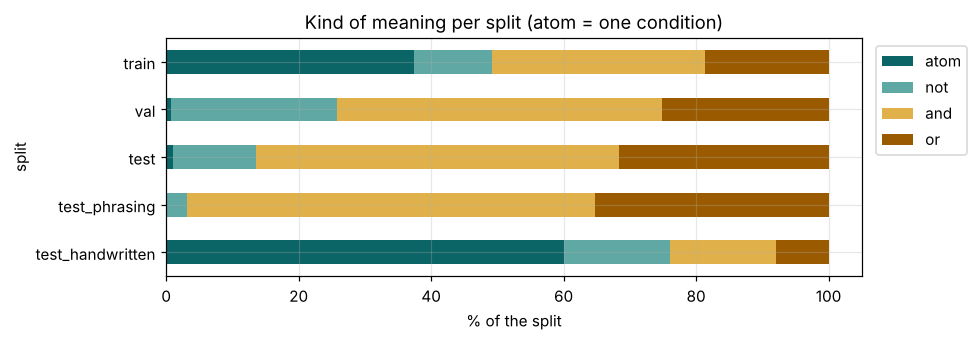

In [13]:
size = df.groupby("split").size().reindex(SPLITS)
kinds = pd.crosstab(df["split"], df["kind"]).reindex(SPLITS)[["atom", "not", "and", "or"]]
kinds_pct = (kinds.div(kinds.sum(axis=1), axis=0) * 100).round(1)
display(pd.concat([size.rename("pairs"), kinds, kinds_pct.add_suffix(" %")], axis=1))
ax = kinds_pct.plot(kind="barh", stacked=True, figsize=(9, 3.2), color=["#0B6465", "#5FA8A3", "#E0B04A", "#9A5B00"])
ax.set_xlabel("% of the split"); ax.set_title("Kind of meaning per split (atom = one condition)"); ax.invert_yaxis()
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()

**Reading.** Training contains the single conditions plus combinations. Because single conditions go to training (the few single-condition rows in validation and test are "fewer than N" conditions, whose regex is a negation), the test set of new regexes is essentially made of combinations and negations, which is the harder, compositional part of the task.

### 5.2 Which conditions and character types occur

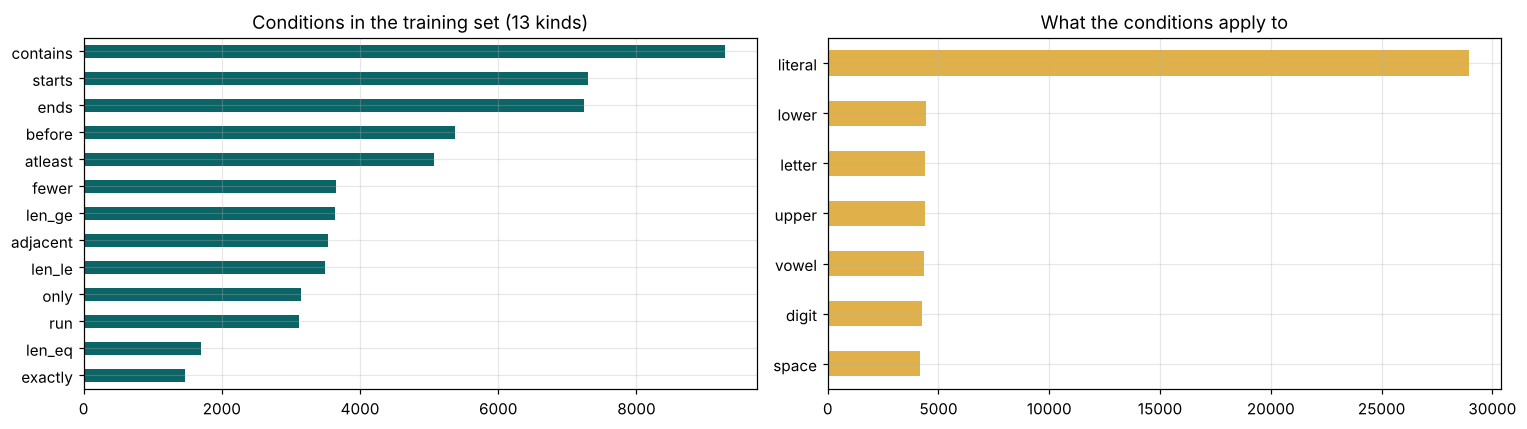

conditions per training example: {1: 18486, 2: 17805, 3: 1295}


In [14]:
def atoms(t):
    if t[0] in ("and", "or"):
        return [a for c in t[1:] for a in atoms(c)]
    if t[0] == "not":
        return atoms(t[1])
    return [t]

def items(a):
    return [x for x in a[1:] if isinstance(x, tuple)]

tr = df[df.split == "train"]
atom_kinds = Counter(a[0] for t in tr.tree_t for a in atoms(t))
item_kinds = Counter(("literal" if it[0] == "lit" else it[1]) for t in tr.tree_t for a in atoms(t) for it in items(a))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(atom_kinds).sort_values().plot(kind="barh", ax=ax[0], color="#0B6465")
ax[0].set_title("Conditions in the training set (13 kinds)")
pd.Series(item_kinds).sort_values().plot(kind="barh", ax=ax[1], color="#E0B04A")
ax[1].set_title("What the conditions apply to")
plt.tight_layout(); plt.show()
n_cond = tr.tree_t.map(lambda t: len(atoms(t)))
print("conditions per training example:", dict(sorted(Counter(n_cond).items())))

### 5.3 Lengths of descriptions and regexes

In [15]:
_SRC_TOKEN = re.compile(r"[a-z0-9_]+(?:-[a-z0-9_]+)*|[^\sa-z0-9_]")


def normalize_src(text):
    """Lowercase and drop quotation marks. Quoted words ('dog', 'truck', ...) are
    placeholders in NL-RX and already identical to the literal used in the regex."""
    text = text.lower().replace("'", " ").replace('"', " ")
    return re.sub(r"\s+", " ", text).strip()


def tokenize_src_veri(text):
    """veriregex preprocessing: placeholders for quoted literals, then lowercase + word tokens"""
    anon, _ = anonymize(text)
    return _SRC_TOKEN.findall(normalize_src(anon))


# regex side: the four placeholder literals and the word boundary '\b' are single tokens,
# every other character is a token on its own.
_TGT_TOKEN = re.compile(r"__w\d__|\\b|dog|truck|ring|lake|.", re.S)


def tokenize_tgt(regex):
    return _TGT_TOKEN.findall(regex)


def detokenize_tgt(tokens):
    return "".join(tokens)

src_len                                          tgt_len                                         
                    count  mean  std  min   25%   50%   75%   max    count  mean   std  min   25%   50%   75%   max
split                                                                                                              
train             37586.0  13.9  4.9  3.0  10.0  13.0  17.0  37.0  37586.0  16.9  10.0  1.0   9.0  16.0  24.0  67.0
val                2000.0  15.8  4.5  4.0  13.0  16.0  19.0  33.0   2000.0  21.5   8.7  8.0  14.0  21.0  27.0  61.0
test               1884.0  16.8  4.2  6.0  14.0  17.0  19.0  33.0   1884.0  22.5   9.0  6.0  16.0  22.0  28.0  66.0
test_phrasing      1500.0  19.3  3.9  7.0  17.0  19.0  22.0  33.0   1500.0  25.9   8.4  6.0  20.0  25.0  31.0  60.0
test_handwritten     50.0   6.9  1.9  3.0   5.2   7.0   8.0  11.0     50.0  11.4   6.8  1.0   6.0  10.5  15.0  31.0

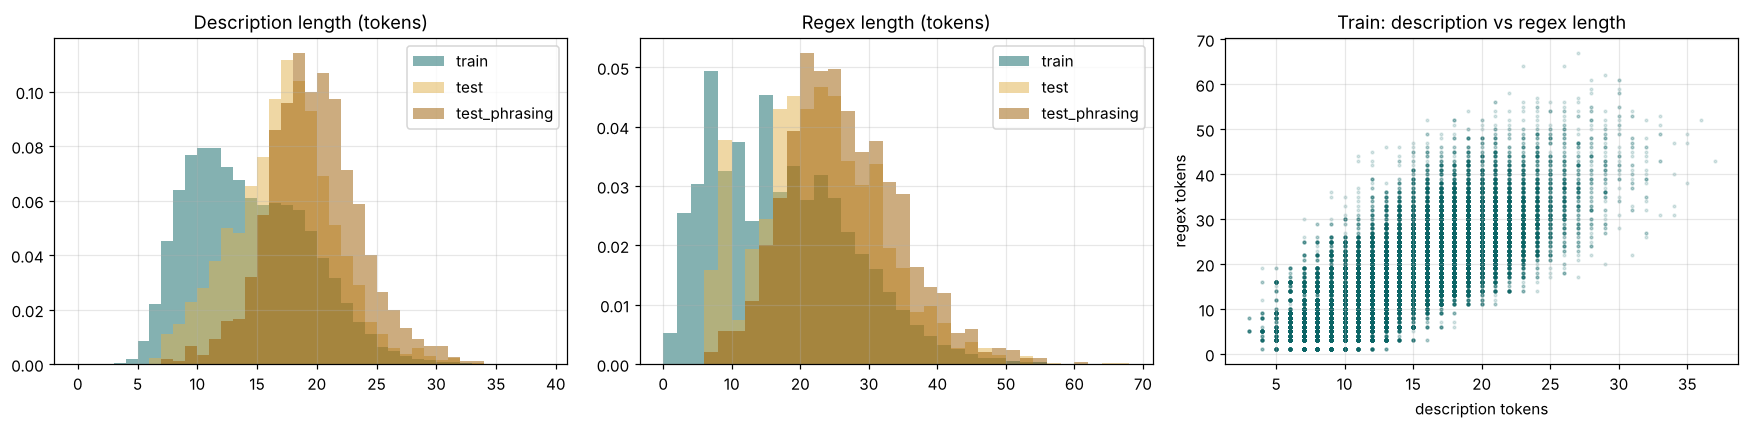

Pearson correlation of description and regex lengths (train): 0.78
regexes longer than the 59-token limit (all splits): 11 of 43020


In [16]:
df["src_tok"] = df.text.map(tokenize_src_veri)
df["tgt_tok"] = df.regex_anon.map(tokenize_tgt)
df["src_len"] = df.src_tok.map(len)
df["tgt_len"] = df.tgt_tok.map(len)
display(df.groupby("split")[["src_len", "tgt_len"]].describe().round(1).reindex(SPLITS))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for s, c in zip(["train", "test", "test_phrasing"], ["#0B6465", "#E0B04A", "#9A5B00"]):
    d = df[df.split == s]
    ax[0].hist(d.src_len, bins=range(0, 40), alpha=0.5, density=True, label=s, color=c)
    ax[1].hist(d.tgt_len, bins=range(0, 70, 2), alpha=0.5, density=True, label=s, color=c)
ax[0].set_title("Description length (tokens)"); ax[1].set_title("Regex length (tokens)")
ax[0].legend(); ax[1].legend()
ax[2].scatter(tr_len := df[df.split == "train"].src_len, df[df.split == "train"].tgt_len, s=3, alpha=0.15, color="#0B6465")
ax[2].set_xlabel("description tokens"); ax[2].set_ylabel("regex tokens"); ax[2].set_title("Train: description vs regex length")
plt.tight_layout(); plt.show()
t = df[df.split == "train"]
print("Pearson correlation of description and regex lengths (train): %.2f" % np.corrcoef(t.src_len, t.tgt_len)[0, 1])
print("regexes longer than the 59-token limit (all splits):", int((df.tgt_len > MAX_TGT_LEN - 1).sum()), "of", len(df))

**Reading.** Descriptions are short (about 14 words) and regexes about 17 tokens, with a long tail for three-condition descriptions. The two lengths are clearly correlated: more conditions means a longer description and a longer regex. Only 11 regexes exceed the output limit of 60 tokens (including the end token).

### 5.4 Vocabulary of the descriptions

distinct words in training descriptions: 194 | tokens: 520736


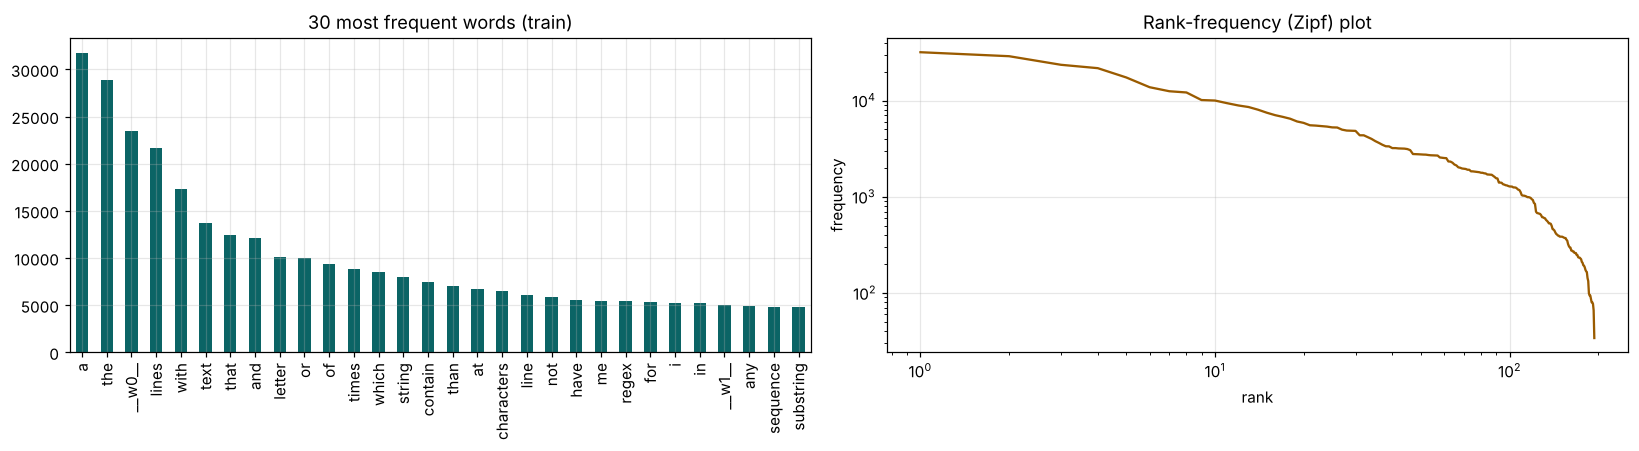

share of tokens covered by the 20 / 50 / 100 most frequent words: 49.2% / 72.1% / 90.7%
val               words never seen in training: 0.00% of tokens  []
test              words never seen in training: 0.00% of tokens  []
test_phrasing     words never seen in training: 0.71% of tokens  [('each', 206)]
test_handwritten  words never seen in training: 1.16% of tokens  [('word', 1), ('whose', 1), ('must', 1), ('be', 1)]


In [17]:
train_counts = Counter(w for toks in df[df.split == "train"].src_tok for w in toks)
print("distinct words in training descriptions:", len(train_counts), "| tokens:", sum(train_counts.values()))
top = pd.Series(dict(train_counts.most_common(30)))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
top.plot(kind="bar", ax=ax[0], color="#0B6465"); ax[0].set_title("30 most frequent words (train)")
freqs = np.array(sorted(train_counts.values(), reverse=True))
ax[1].loglog(np.arange(1, len(freqs) + 1), freqs, color="#9A5B00"); ax[1].set_xlabel("rank"); ax[1].set_ylabel("frequency")
ax[1].set_title("Rank-frequency (Zipf) plot")
plt.tight_layout(); plt.show()
cum = np.cumsum(freqs) / freqs.sum()
print("share of tokens covered by the 20 / 50 / 100 most frequent words: %.1f%% / %.1f%% / %.1f%%"
      % (100 * cum[19], 100 * cum[49], 100 * cum[99]))
for s in SPLITS[1:]:
    toks = [w for t_ in df[df.split == s].src_tok for w in t_]
    unk = [w for w in toks if w not in train_counts]
    print(f"{s:17s} words never seen in training: {100 * len(unk) / len(toks):.2f}% of tokens  {Counter(unk).most_common(6)}")

**Reading.** The vocabulary is small (about 200 words) because the language is generated, and a few function words (`lines`, `that`, `__w0__`, `the`) dominate. The two test sets of new regexes have no unknown words, the held-out phrasings almost none (`each`), and the handwritten set about 1%, which is where robustness to new wording is really tested.

### 5.5 Literals, numbers and target symbols

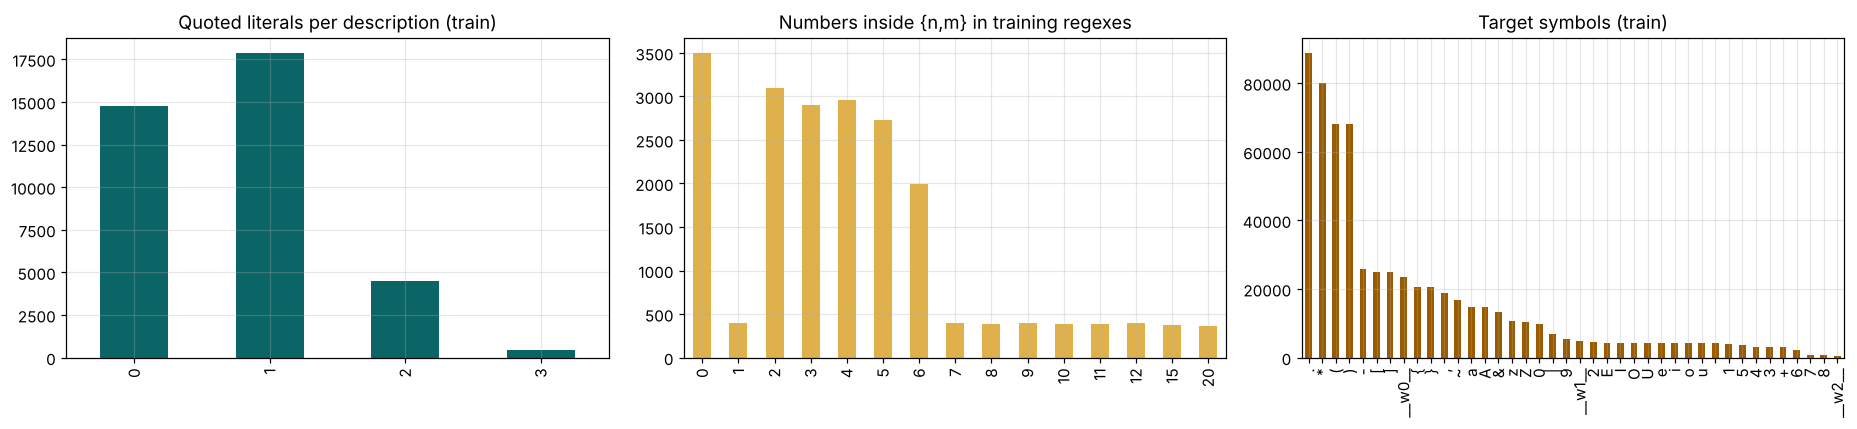

distinct literal values: 135 | most common: [('ice cream', 318), ('Bob', 308), ('USA', 300), ('good morning', 298), ('big data', 294), ('Tunis', 294), ('Python', 290), ('Monday', 288)]


In [18]:
n_lits = df[df.split == "train"].words.map(len)
lit_words = Counter(w for ws in df[df.split == "train"].words for w in ws)
nums = Counter(int(n) for t in df[df.split == "train"].regex_anon for n in re.findall(r"\{(\d+)", t))
tgt_counts = Counter(tok for toks in df[df.split == "train"].tgt_tok for tok in toks)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pd.Series(Counter(n_lits)).sort_index().plot(kind="bar", ax=ax[0], color="#0B6465"); ax[0].set_title("Quoted literals per description (train)")
pd.Series(nums).sort_index().plot(kind="bar", ax=ax[1], color="#E0B04A"); ax[1].set_title("Numbers inside {n,m} in training regexes")
pd.Series(dict(tgt_counts.most_common())).plot(kind="bar", ax=ax[2], color="#9A5B00"); ax[2].set_title("Target symbols (train)")
plt.tight_layout(); plt.show()
print("distinct literal values:", len(lit_words), "| most common:", lit_words.most_common(8))

**Reading.** Most descriptions have zero to two literals; numbers range from 1 to 20 (counts 2 to 6, lengths 1 to 20). The target alphabet is tiny: `.`, `*`, parentheses, brackets, braces, class ranges, `&`, `|`, `~` and the slots.

### 5.6 Phrasing diversity

In [19]:
t = df[df.split == "train"].copy()
t["pattern"] = t.text.map(lambda s: re.sub(r"\b\d+\b", "N", anonymize(s)[0].lower()))
per_rx = t.groupby("regex_anon").size()
print("training pairs:", len(t), "| distinct descriptions:", t.text.nunique(),
      "| distinct sentence patterns (literals and numbers abstracted):", t.pattern.nunique())
print("distinct regex structures:", t.regex_anon.nunique(), "| descriptions per structure: mean %.2f, max %d" % (per_rx.mean(), per_rx.max()))
rx = t.regex_anon.value_counts().index[0]
display(pd.DataFrame({"descriptions of the most frequent structure " + rx: t[t.regex_anon == rx].text.head(8).values}))

training pairs: 37586 | distinct descriptions: 37586 | distinct sentence patterns (literals and numbers abstracted): 37323
distinct regex structures: 14345 | descriptions per structure: mean 2.62, max 996


,descriptions of the most frequent structure .*__w0__.*
0,get lines with the text 'tree'
1,show me lines having 'dog'
2,I need any text including 'yes'
3,select text lines that have the substring 'login'
4,give me all lines having 'gray'
5,"match text lines that contain the text ""est"" somewhere"
6,"regex matching every line containing the sequence ""train"""
7,I want all lines that have the sequence 'z'


**Reading.** Nearly every training sentence is different, and one regex is expressed in many different ways (the table shows one structure), so the model cannot simply memorise sentence-to-regex pairs.

### 5.7 Leakage checks

In [20]:
sets = {s: set(df[df.split == s].regex_anon) for s in SPLITS}
srcs = {s: set(df[df.split == s].src_tok.map(" ".join)) for s in SPLITS}
rows = []
for s in SPLITS[1:]:
    rows.append({"split": s, "regexes also in train": len(sets[s] & sets["train"]),
                 "distinct regexes": len(sets[s]), "descriptions also in train": len(srcs[s] & srcs["train"])})
display(pd.DataFrame(rows))

,split,regexes also in train,distinct regexes,descriptions also in train
0,val,0,1137,0
1,test,0,1194,0
2,test_phrasing,0,1426,0
3,test_handwritten,41,45,4


**Reading.** Validation, test and held-out-phrasing regexes never occur in training (0 overlap), and none of their descriptions does either. The handwritten set is different by design: 41 of its 45 distinct regexes (46 of its 50 examples) are known from training, and 4 of its simplest descriptions (such as "lines containing 'ice cream'" once the literal is replaced by a slot) can also be produced by the generator. It tests free wording, not new structure.

## 6. Preprocessing

| Step | What we do | Why |
|---|---|---|
| Literal slots | each quoted span (`'cat'`, `"2024"`, `'ice cream'`) becomes `__w0__`, `__w1__`, ... in order of first appearance, in the description **and** in the regex; slots are replaced by the literals after decoding (special characters escaped as `[.]`) | the model works with any word, including words never seen in training |
| Normalisation | lowercase, remaining quotes removed (so `don't` becomes `don t`) | smaller vocabulary |
| Source tokenisation | words (hyphenated words kept whole) and punctuation | |
| Target tokenisation | one token per regex character; `__wK__` and `\b` are single tokens | regex syntax is character-level |
| Vocabularies | built on the training split only; `<PAD>`=0, `<UNK>`=1, `<SOS>`=2, `<EOS>`=3 | no information from the test sets |
| Encoding | token ids, then a learned embedding layer (dimension 128) | |
| Padding and batching | batches padded with `<PAD>`, grouped by target length; the encoder uses packed sequences, attention masks padding, the loss ignores it | variable-length batches, less padding |
| Truncation | at most 40 source and 60 target tokens | |
| Unknown words | `<UNK>`, plus 5% word dropout during training (random words replaced by `<UNK>`) | robustness to unseen words |

### 6.1 Literal slots

In [21]:
for s in ["lines that don't contain 'dog' or \"2024\"",
          "lines with \u2018ice cream\u2019 and 'dog', then 'dog' again",
          "lines where 'blue' comes somewhere after 'red'",
          "lines containing 'a.b'"]:
    anon, lits = anonymize(s)
    print(f"{s}\n   -> {anon.strip()!r}   literals={lits}")
print()
print("put back after decoding:", deanonymize(".*__w0__.*__w1__.*", ["red", "blue"]), "|", deanonymize(".*__w0__.*", ["a.b"]))

lines that don't contain 'dog' or "2024"
   -> "lines that don't contain  __w0__  or  __w1__"   literals=['dog', '2024']
lines with ‘ice cream’ and 'dog', then 'dog' again
   -> 'lines with  __w0__  and  __w1__ , then  __w1__  again'   literals=['ice cream', 'dog']
lines where 'blue' comes somewhere after 'red'
   -> 'lines where  __w0__  comes somewhere after  __w1__'   literals=['blue', 'red']
lines containing 'a.b'
   -> 'lines containing  __w0__'   literals=['a.b']

put back after decoding: .*red.*blue.* | .*a[.]b.*


### 6.2 Normalisation and tokenisation

In [22]:
ex = raw["train"][3]
print("description :", ex["text"])
print("tokens      :", tokenize_src_veri(ex["text"]))
print("regex       :", ex["regex"])
print("slot regex  :", ex["regex_anon"])
print("tokens      :", tokenize_tgt(ex["regex_anon"]))
bad = [r for r in df.regex_anon if detokenize_tgt(tokenize_tgt(r)) != r]
print("tokenisation round-trip failures on all", len(df), "regexes:", len(bad))

description : lines where the sequence 'NASA' appears or a letter of the alphabet appears at least 5 times
tokens      : ['lines', 'where', 'the', 'sequence', '__w0__', 'appears', 'or', 'a', 'letter', 'of', 'the', 'alphabet', 'appears', 'at', 'least', '5', 'times']
regex       : (.*NASA.*)|((.*[A-Za-z]){5,}.*)
slot regex  : (.*__w0__.*)|((.*[A-Za-z]){5,}.*)
tokens      : ['(', '.', '*', '__w0__', '.', '*', ')', '|', '(', '(', '.', '*', '[', 'A', '-', 'Z', 'a', '-', 'z', ']', ')', '{', '5', ',', '}', '.', '*', ')']


tokenisation round-trip failures on all 43020 regexes: 0


### 6.3 Vocabularies, encoding, padding and batching

In [23]:
# ------------------------------------------------------------------------ vocabulary
class Vocab:
    def __init__(self, tokens=None):
        self.itos = list(SPECIALS)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        for t in tokens or []:
            if t not in self.stoi:
                self.stoi[t] = len(self.itos)
                self.itos.append(t)

    @classmethod
    def build(cls, sequences, min_freq=1):
        counts = {}
        for seq in sequences:
            for t in seq:
                counts[t] = counts.get(t, 0) + 1
        kept = sorted([t for t, c in counts.items() if c >= min_freq], key=lambda t: (-counts[t], t))
        return cls(kept)

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        return [self.stoi.get(t, UNK_ID) for t in tokens]

    def decode(self, ids, stop_at_eos=True):
        out = []
        for i in ids:
            if i == EOS_ID and stop_at_eos:
                break
            if i in (PAD_ID, SOS_ID, EOS_ID):
                continue
            out.append(self.itos[i])
        return out


def build_veri(seed=42, min_freq=1, **_):
    """veriregex splits are fixed by src/generate.py (split by regex); `seed` is unused."""
    splits = {}
    for name in ("train", "val", "test", "test_phrasing", "test_handwritten"):
        rows = []
        for line in (DATA / f"{name}.jsonl").read_text(encoding="utf-8").splitlines():
            ex = json.loads(line)
            rows.append({"src_raw": ex["text"], "tgt_raw": ex["regex_anon"], "regex": ex["regex"],
                         "src_tok": tokenize_src_veri(ex["text"]), "tgt_tok": tokenize_tgt(ex["regex_anon"]),
                         "kind": ex["kind"], "words": ex["words"]})
        splits[name] = rows
    src_vocab = Vocab.build([r["src_tok"] for r in splits["train"]], min_freq=min_freq)
    tgt_vocab = Vocab.build([r["tgt_tok"] for r in splits["train"]])
    for split in splits.values():
        for r in split:
            r["src_ids"] = src_vocab.encode(r["src_tok"][:MAX_SRC_LEN])
            r["tgt_ids"] = [SOS_ID] + tgt_vocab.encode(r["tgt_tok"][:MAX_TGT_LEN - 1]) + [EOS_ID]
    train_targets = {r["tgt_raw"] for r in splits["train"]}
    for name, split in splits.items():
        for r in split:
            r["unseen_target"] = r["tgt_raw"] not in train_targets

    def unk_rate(rows):
        total = sum(len(r["src_ids"]) for r in rows)
        return sum(i == UNK_ID for r in rows for i in r["src_ids"]) / max(1, total)
    allrows = [r for s in splits.values() for r in s]
    stats = {"dataset": "veriregex", **{k: len(v) for k, v in splits.items()},
             "src_vocab_size": len(src_vocab), "tgt_vocab_size": len(tgt_vocab),
             "avg_src_tokens": sum(len(r["src_tok"]) for r in splits["train"]) / len(splits["train"]),
             "max_src_tokens": max(len(r["src_tok"]) for r in allrows),
             "avg_tgt_tokens": sum(len(r["tgt_tok"]) for r in splits["train"]) / len(splits["train"]),
             "max_tgt_tokens": max(len(r["tgt_tok"]) for r in allrows),
             "n_truncated_src": sum(len(r["src_tok"]) > MAX_SRC_LEN for r in allrows),
             "n_truncated_tgt": sum(len(r["tgt_tok"]) > MAX_TGT_LEN - 1 for r in allrows),
             "unique_targets_train": len(train_targets),
             **{f"unk_rate_{k}": unk_rate(v) for k, v in splits.items() if k != "train"},
             **{f"unseen_target_frac_{k}": sum(r["unseen_target"] for r in v) / max(1, len(v))
                for k, v in splits.items() if k != "train"}}
    return {"splits": splits, "src_vocab": src_vocab, "tgt_vocab": tgt_vocab, "stats": stats}


# ----------------------------------------------------------------------------- batches
def collate(rows):
    src = pad_sequence([torch.tensor(r["src_ids"] or [UNK_ID]) for r in rows],
                       batch_first=True, padding_value=PAD_ID)
    src_len = torch.tensor([max(1, len(r["src_ids"])) for r in rows])
    tgt = pad_sequence([torch.tensor(r["tgt_ids"]) for r in rows],
                       batch_first=True, padding_value=PAD_ID)
    return src, src_len, tgt


def batches(rows, batch_size, shuffle=False, rng=None, bucket=True):
    """Yield (rows, src, src_len, tgt). When shuffling, examples are bucketed by target length inside
    large random chunks so that a batch contains sequences of similar length (less padding, faster)."""
    order = list(range(len(rows)))
    if shuffle:
        (rng or random).shuffle(order)
        if bucket:
            chunk_size = batch_size * 20
            order = [j for i in range(0, len(order), chunk_size)
                     for j in sorted(order[i:i + chunk_size], key=lambda k: len(rows[k]["tgt_ids"]))]
    chunks = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    if shuffle:
        (rng or random).shuffle(chunks)
    for ch in chunks:
        chunk = [rows[j] for j in ch]
        yield chunk, *collate(chunk)

In [24]:
def get_data(dataset="veriregex", seed=42, **_):
    return build_veri(seed)

data = get_data()
src_vocab, tgt_vocab = data["src_vocab"], data["tgt_vocab"]
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in data["stats"].items()}, indent=1))
print("\nspecial tokens:", src_vocab.itos[:4], "| first words:", src_vocab.itos[4:20])
print("target vocabulary (%d):" % len(tgt_vocab), tgt_vocab.itos)
r = data["splits"]["train"][3]
print("\nencoded source:", r["src_ids"])
print("encoded target:", r["tgt_ids"], "->", tgt_vocab.decode(r["tgt_ids"]))

{
 "dataset": "veriregex",
 "train": 37586,
 "val": 2000,
 "test": 1884,
 "test_phrasing": 1500,
 "test_handwritten": 50,
 "src_vocab_size": 198,
 "tgt_vocab_size": 44,
 "avg_src_tokens": 13.8545,
 "max_src_tokens": 37,
 "avg_tgt_tokens": 16.9341,
 "max_tgt_tokens": 67,
 "n_truncated_src": 0,
 "n_truncated_tgt": 11,
 "unique_targets_train": 14345,
 "unk_rate_val": 0.0,
 "unk_rate_test": 0.0,
 "unk_rate_test_phrasing": 0.0071,
 "unk_rate_test_handwritten": 0.0116,
 "unseen_target_frac_val": 1.0,
 "unseen_target_frac_test": 1.0,
 "unseen_target_frac_test_phrasing": 1.0,
 "unseen_target_frac_test_handwritten": 0.08
}

special tokens: ['<PAD>', '<UNK>', '<SOS>', '<EOS>'] | first words: ['a', 'the', '__w0__', 'lines', 'with', 'text', 'that', 'and', 'letter', 'or', 'of', 'times', 'which', 'string', 'contain', 'than']
target vocabulary (44): ['<PAD>', '<UNK>', '<SOS>', '<EOS>', '.', '*', '(', ')', '-', '[', ']', '__w0__', '{', '}', ',', '~', 'a', 'A', '&', 'z', 'Z', '0', '|', '9', '__w1__', '

In [25]:
# a padded batch, as fed to the model
batch_rows, src, src_len, tgt = next(batches(data["splits"]["train"][:8], 4))
print("src", tuple(src.shape), "src_len", src_len.tolist(), "tgt", tuple(tgt.shape))
print(src)
print("padding share in shuffled, length-bucketed training batches:",
      round(float(np.mean([(t == PAD_ID).float().mean().item() for _, _, _, t in batches(data["splits"]["train"], 64, shuffle=True, rng=random.Random(0))])), 3),
      "vs. unbucketed:",
      round(float(np.mean([(t == PAD_ID).float().mean().item() for _, _, _, t in batches(data["splits"]["train"], 64, shuffle=True, rng=random.Random(0), bucket=False)])), 3))

src (4, 19) src_len [16, 19, 15, 17] tgt (4, 35)
tensor([[  7,   8,  87, 101,  21,  13,   8,   5,  17,   6,  74,  44,  43,   4,
          80,  12,   0,   0,   0],
        [ 52,   7,  14,   9,  10,  24,   4,  90,  12,  84,  79,   4,  36,  13,
          24,  20,  35, 164,  21],
        [ 31,  22, 112,  73, 118, 119,  14,   6,  11,  23, 100,  63,  14,  83,
          65,   0,   0,   0,   0],
        [  7,  34,   5,  32,   6,  72,  13,   4,  12,  14,   5,  97,  72,  20,
          35,  85,  15,   0,   0]])


padding share in shuffled, length-bucketed training batches: 0.063 vs. unbucketed: 0.582


## 7. Model

- **Encoder:** `Embedding(198, 128)` -> dropout -> `LSTM(128 -> 256)`, packed sequences.
- **Bridge:** the encoder's final $(h, c)$, each through a linear layer and $\tanh$, initialise the decoder.
- **Decoder, baseline:** `Embedding(44, 128)` -> `LSTM(256)` -> `Linear(256 -> 44)` -> softmax. Its only link to the input is the initial state: one fixed-size vector must summarise the whole description.
- **Decoder with attention (Bahdanau):** at each step $e_{t,i} = v^\top \tanh(W_s s_t + W_h h_i)$, $\alpha_t = \mathrm{softmax}(e_t)$ (padding masked), context $c_t = \sum_i \alpha_{t,i} h_i$. The context is fed to the LSTM with the previous token, and the output layer sees $[s_t; c_t; \mathrm{emb}(y_{t-1})]$.
- **Training:** teacher forcing (the gold previous token is fed). **Inference:** greedy arg-max or beam search, stopping at `<EOS>` or after 60 tokens.

In [26]:
def make_rnn(kind, input_size, hidden, layers, bidirectional=False, dropout=0.0):
    cls = {"lstm": nn.LSTM, "gru": nn.GRU}[kind]
    return cls(input_size, hidden, num_layers=layers, batch_first=True,
               bidirectional=bidirectional, dropout=dropout if layers > 1 else 0.0)


class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim, layers, rnn="lstm", bidirectional=False, dropout=0.2):
        super().__init__()
        self.rnn_kind, self.layers, self.bidir = rnn, layers, bidirectional
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.dropout = nn.Dropout(dropout)
        self.rnn = make_rnn(rnn, emb_dim, hid_dim, layers, bidirectional, dropout)
        self.out_dim = hid_dim * (2 if bidirectional else 1)

    def forward(self, src, src_len):
        emb = self.dropout(self.embedding(src))
        packed = nn.utils.rnn.pack_padded_sequence(emb, src_len.cpu(), batch_first=True, enforce_sorted=False)
        out, state = self.rnn(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=src.size(1))
        return out, state  # out: [B, S, H*dirs]; state: (h, c) or h with shape [L*dirs, B, H]


class AdditiveAttention(nn.Module):
    """score(s_t, h_i) = v^T tanh(W_s s_t + W_h h_i);  alpha = softmax(score);  ctx = sum alpha_i h_i"""

    def __init__(self, enc_dim, dec_dim, att_dim):
        super().__init__()
        self.W_h = nn.Linear(enc_dim, att_dim, bias=False)
        self.W_s = nn.Linear(dec_dim, att_dim, bias=True)
        self.v = nn.Linear(att_dim, 1, bias=False)

    def forward(self, dec_hidden, enc_out, mask, enc_proj=None):
        # dec_hidden: [B, H]; enc_out: [B, S, E]; mask: [B, S] (True = real token)
        if enc_proj is None:
            enc_proj = self.W_h(enc_out)
        scores = self.v(torch.tanh(enc_proj + self.W_s(dec_hidden).unsqueeze(1))).squeeze(-1)
        scores = scores.masked_fill(~mask, float("-inf"))   # padding gets zero weight
        alpha = F.softmax(scores, dim=-1)
        ctx = torch.bmm(alpha.unsqueeze(1), enc_out).squeeze(1)
        return ctx, alpha


class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim, layers, enc_dim, rnn="lstm",
                 attention=False, att_dim=None, dropout=0.2):
        super().__init__()
        self.rnn_kind, self.layers, self.use_attention = rnn, layers, attention
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.dropout = nn.Dropout(dropout)
        rnn_in = emb_dim + (enc_dim if attention else 0)
        self.rnn = make_rnn(rnn, rnn_in, hid_dim, layers, False, dropout)
        self.attention = AdditiveAttention(enc_dim, hid_dim, att_dim or hid_dim) if attention else None
        out_in = hid_dim + (enc_dim + emb_dim if attention else 0)
        self.out = nn.Linear(out_in, vocab_size)

    def step(self, prev_tok, state, enc_out=None, mask=None, enc_proj=None):
        """One decoding step. prev_tok: [B]. Returns logits [B, V], new state, attention [B, S] or None."""
        emb = self.dropout(self.embedding(prev_tok)).unsqueeze(1)           # [B, 1, E]
        alpha = None
        if self.use_attention:
            top = state[0][-1] if self.rnn_kind == "lstm" else state[-1]      # last layer hidden [B, H]
            ctx, alpha = self.attention(top, enc_out, mask, enc_proj)
            rnn_in = torch.cat([emb, ctx.unsqueeze(1)], dim=-1)
        else:
            rnn_in = emb
        out, state = self.rnn(rnn_in, state)
        h = out.squeeze(1)
        feats = torch.cat([h, ctx, emb.squeeze(1)], dim=-1) if self.use_attention else h
        return self.out(self.dropout(feats)), state, alpha


class Seq2Seq(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, emb_dim=128, hid_dim=256, layers=1, rnn="lstm",
                 bidirectional=False, attention=False, dropout=0.2, word_dropout=0.0):
        super().__init__()
        self.word_dropout = word_dropout
        self.cfg = dict(src_vocab=src_vocab, tgt_vocab=tgt_vocab, emb_dim=emb_dim, hid_dim=hid_dim,
                        layers=layers, rnn=rnn, bidirectional=bidirectional, attention=attention,
                        dropout=dropout, word_dropout=word_dropout)
        self.rnn_kind, self.layers, self.hid = rnn, layers, hid_dim
        self.encoder = Encoder(src_vocab, emb_dim, hid_dim, layers, rnn, bidirectional, dropout)
        self.decoder = Decoder(tgt_vocab, emb_dim, hid_dim, layers, self.encoder.out_dim, rnn,
                               attention, hid_dim, dropout)
        # bridge: maps the encoder final state (possibly 2 directions concatenated) to the decoder size
        self.bridge_h = nn.Linear(self.encoder.out_dim, hid_dim)
        self.bridge_c = nn.Linear(self.encoder.out_dim, hid_dim) if rnn == "lstm" else None

    # ------------------------------------------------------------------ encoding
    def _bridge_one(self, h, layer):
        # h: [L*dirs, B, H]  ->  [L, B, H_dec]
        L, d = self.layers, 2 if self.encoder.bidir else 1
        h = h.view(L, d, h.size(1), h.size(2))
        h = torch.cat([h[:, i] for i in range(d)], dim=-1)      # concat directions
        return torch.tanh(layer(h))

    def encode(self, src, src_len):
        enc_out, state = self.encoder(src, src_len)
        if self.rnn_kind == "lstm":
            state = (self._bridge_one(state[0], self.bridge_h), self._bridge_one(state[1], self.bridge_c))
        else:
            state = self._bridge_one(state, self.bridge_h)
        mask = src != PAD_ID
        enc_proj = self.decoder.attention.W_h(enc_out) if self.decoder.use_attention else None
        return enc_out, state, mask, enc_proj

    # ------------------------------------------------------------------- training
    def forward(self, src, src_len, tgt, tf_ratio=1.0):
        """tgt: [B, T] = <SOS> w1 ... wn <EOS> <PAD>*. Returns logits for positions 1..T-1: [B, T-1, V]."""
        if self.training and self.word_dropout > 0:   # randomly replace input words by <UNK>
            drop = (torch.rand(src.shape) < self.word_dropout) & (src != PAD_ID)
            src = src.masked_fill(drop, UNK_ID)
        enc_out, state, mask, enc_proj = self.encode(src, src_len)
        B, T = tgt.shape
        prev = tgt[:, 0]
        logits = []
        for t in range(1, T):
            out, state, _ = self.decoder.step(prev, state, enc_out, mask, enc_proj)
            logits.append(out)
            # teacher forcing: with prob tf_ratio feed the gold token, otherwise the model's own prediction
            if tf_ratio >= 1.0 or random.random() < tf_ratio:
                prev = tgt[:, t]
            else:
                prev = out.argmax(-1)
        return torch.stack(logits, dim=1)

    # ------------------------------------------------------------------ inference
    @torch.no_grad()
    def greedy_decode(self, src, src_len, max_len=60, return_attention=False):
        """Batched greedy decoding: pick the arg-max token at every step, stop at <EOS>."""
        self.eval()
        enc_out, state, mask, enc_proj = self.encode(src, src_len)
        B = src.size(0)
        prev = torch.full((B,), SOS_ID, dtype=torch.long, device=src.device)
        done = torch.zeros(B, dtype=torch.bool, device=src.device)
        tokens, atts = [], []
        for _ in range(max_len):
            out, state, alpha = self.decoder.step(prev, state, enc_out, mask, enc_proj)
            prev = out.argmax(-1)
            prev = prev.masked_fill(done, PAD_ID)
            tokens.append(prev)
            if alpha is not None:
                atts.append(alpha)
            done = done | (prev == EOS_ID)
            if done.all():
                break
        tokens = torch.stack(tokens, dim=1)
        if return_attention and atts:
            return tokens, torch.stack(atts, dim=1)   # [B, T, S]
        return tokens

    @torch.no_grad()
    def beam_search(self, src, src_len, beam=5, max_len=60, length_norm=True):
        """Beam search for ONE example (batch size 1). Returns the best token-id list (without <SOS>/<EOS>)."""
        self.eval()
        enc_out, state, mask, enc_proj = self.encode(src, src_len)
        dev = src.device
        is_lstm = self.rnn_kind == "lstm"
        hyps = [([SOS_ID], 0.0, state)]          # (tokens, sum of log-probs, decoder state [L,1,H])
        finished = []                            # (tokens, score)
        for _ in range(max_len):
            n = len(hyps)
            prev = torch.tensor([h[0][-1] for h in hyps], device=dev)
            if is_lstm:
                st = (torch.cat([h[2][0] for h in hyps], dim=1), torch.cat([h[2][1] for h in hyps], dim=1))
            else:
                st = torch.cat([h[2] for h in hyps], dim=1)
            ep = enc_proj.expand(n, -1, -1) if enc_proj is not None else None
            out, new_state, _ = self.decoder.step(prev, st, enc_out.expand(n, -1, -1), mask.expand(n, -1), ep)
            logp = F.log_softmax(out, dim=-1)
            cands = []
            for i, (_, score, _) in enumerate(hyps):
                lp, ids = logp[i].topk(beam)
                cands.extend((score + l, i, t) for l, t in zip(lp.tolist(), ids.tolist()))
            cands.sort(key=lambda c: -c[0])
            new_hyps = []
            for score, i, tid in cands:
                toks = hyps[i][0] + [tid]
                if tid == EOS_ID:
                    finished.append((toks[1:-1], score))
                else:
                    if is_lstm:
                        s_i = (new_state[0][:, i:i + 1].contiguous(), new_state[1][:, i:i + 1].contiguous())
                    else:
                        s_i = new_state[:, i:i + 1].contiguous()
                    new_hyps.append((toks, score, s_i))
                if len(new_hyps) == beam:
                    break
            hyps = new_hyps
            # stop when no live hypothesis can still beat the best finished one (log-probs only go down)
            if not hyps or (finished and max(f[1] for f in finished) >= max(h[1] for h in hyps)):
                break
        if not finished:
            finished = [(h[0][1:], h[1]) for h in hyps]
        key = (lambda f: f[1] / max(1, len(f[0]) + 1)) if length_norm else (lambda f: f[1])
        return max(finished, key=key)[0]

In [27]:
def param_table(model):
    rows = [{"module": n, "shape": tuple(p.shape), "parameters": p.numel()} for n, p in model.named_parameters()]
    return pd.DataFrame(rows)

for att in (False, True):
    m = Seq2Seq(len(src_vocab), len(tgt_vocab), 128, 256, 1, "lstm", False, att, 0.3, 0.05)
    t_ = param_table(m)
    print(("WITH" if att else "WITHOUT") + f" attention: {t_.parameters.sum():,} parameters")
    t_["block"] = t_.module.str.split(".").str[0] + "." + t_.module.str.split(".").str[1]
    display(t_.groupby("block", sort=False).parameters.sum().to_frame().T)

WITHOUT attention: 964,396 parameters


block,encoder.embedding,encoder.rnn,decoder.embedding,decoder.rnn,decoder.out,bridge_h.weight,bridge_h.bias,bridge_c.weight,bridge_c.bias
parameters,25344,395264,5632,395264,11308,65536,256,65536,256


WITH attention: 1,375,020 parameters


block,encoder.embedding,encoder.rnn,decoder.embedding,decoder.rnn,decoder.attention,decoder.out,bridge_h.weight,bridge_h.bias,bridge_c.weight,bridge_c.bias
parameters,25344,395264,5632,657408,131584,28204,65536,256,65536,256


## 8. Training

Same procedure as `src/train.py`: token-level cross-entropy (padding ignored), Adam (learning rate 1e-3, halved when the validation loss stops improving for 2 epochs), gradient clipping at 1.0, batch size 64, dropout 0.3, word dropout 0.05, teacher forcing ratio 1.0. After each epoch we compute validation loss, perplexity and greedy exact match; the checkpoint with the best validation exact match is kept, with early stopping.

- **Baseline (no attention):** up to 30 epochs, patience 6 (it is still improving at 15 epochs).
- **Attention:** up to 15 epochs, patience 4.

In [28]:
# ------------------------------------------------------------------------- generation
@torch.no_grad()
def predict(model, rows, tgt_vocab, mode="greedy", beam=5, batch_size=128, keep_attention=False):
    """Returns a list of dicts {tokens, text, attention (optional)} aligned with `rows`."""
    model.eval()
    out = []
    if mode == "greedy":
        for i in range(0, len(rows), batch_size):
            chunk = rows[i:i + batch_size]
            src, src_len, _ = collate(chunk)
            res = model.greedy_decode(src, src_len, return_attention=keep_attention)
            toks, att = res if isinstance(res, tuple) else (res, None)
            for k in range(len(chunk)):
                t = tgt_vocab.decode(toks[k].tolist())
                item = {"tokens": t, "text": detokenize_tgt(t)}
                if att is not None:
                    item["attention"] = att[k, :len(t) + 1, :len(chunk[k]["src_ids"])].cpu()
                out.append(item)
    elif mode == "beam":
        for r in rows:
            src, src_len, _ = collate([r])
            ids = model.beam_search(src, src_len, beam=beam)
            t = tgt_vocab.decode(ids)
            out.append({"tokens": t, "text": detokenize_tgt(t)})
    else:
        raise ValueError(mode)
    return out


# ---------------------------------------------------------------------------- metrics
def corpus_bleu(hyps, refs, max_n=4):
    """Corpus BLEU on token lists with add-one smoothing for n>1 (so short outputs do not give 0)."""
    clipped, total = [0] * max_n, [0] * max_n
    hyp_len = ref_len = 0
    for h, r in zip(hyps, refs):
        hyp_len += len(h)
        ref_len += len(r)
        for n in range(1, max_n + 1):
            hc = Counter(tuple(h[i:i + n]) for i in range(len(h) - n + 1))
            rc = Counter(tuple(r[i:i + n]) for i in range(len(r) - n + 1))
            clipped[n - 1] += sum(min(c, rc[g]) for g, c in hc.items())
            total[n - 1] += max(0, len(h) - n + 1)
    if hyp_len == 0:
        return 0.0
    logp = 0.0
    for n in range(max_n):
        num, den = clipped[n], total[n]
        if n > 0:
            num, den = num + 1, den + 1
        if num == 0 or den == 0:
            return 0.0
        logp += math.log(num / den) / max_n
    bp = 1.0 if hyp_len > ref_len else math.exp(1 - ref_len / hyp_len)
    return 100.0 * bp * math.exp(logp)


@torch.no_grad()
def teacher_forced_stats(model, rows, batch_size=128):
    """Token-level cross-entropy, perplexity and next-token accuracy with gold prefixes."""
    model.eval()
    loss_sum = correct = n_tok = 0
    for _, src, src_len, tgt in batches(rows, batch_size):
        logits = model(src, src_len, tgt, 1.0)
        gold = tgt[:, 1:]
        mask = gold != PAD_ID
        loss_sum += F.cross_entropy(logits.reshape(-1, logits.size(-1)), gold.reshape(-1),
                                    ignore_index=PAD_ID, reduction="sum").item()
        correct += ((logits.argmax(-1) == gold) & mask).sum().item()
        n_tok += mask.sum().item()
    loss = loss_sum / n_tok
    return {"loss": loss, "perplexity": math.exp(loss), "token_acc": correct / n_tok}


PROBE_WORDS = ["dog", "truck", "ring"]   # placeholders are replaced by these words for behavioural tests


def probe_form(rx):
    return re.sub(r"__w(\d)__", lambda m: PROBE_WORDS[int(m.group(1))] if int(m.group(1)) < 3 else "lake", rx)


def evaluate_split(model, rows, tgt_vocab, mode="greedy", beam=5, functional=True, probe_strings=None):
    preds = predict(model, rows, tgt_vocab, mode, beam)
    refs = [r["tgt_raw"] for r in rows]
    em = [p["text"] == ref for p, ref in zip(preds, refs)]
    res = {"mode": mode if mode == "greedy" else f"beam{beam}", "n": len(rows),
           "exact_match": sum(em) / len(rows),
           "bleu": corpus_bleu([p["tokens"] for p in preds], [r["tgt_tok"] for r in rows])}
    func = valid = degen = None
    if functional:
        probe_strings = probe_strings or make_test_strings()
        ref_sigs = {}
        func, valid, degen = [], [], []
        for p, ref in zip(preds, refs):
            if ref not in ref_sigs:
                ref_sigs[ref] = signature(probe_form(ref), probe_strings)
            # a reference that accepts none (or all) of the probes is "degenerate": a prediction that
            # also accepts none (or all) is then judged equivalent too, which inflates functional accuracy
            degen.append(sum(ref_sigs[ref]) in (0, len(probe_strings)))
            sig = signature(probe_form(p["text"]), probe_strings)
            valid.append(sig is not None)
            func.append(sig is not None and sig == ref_sigs[ref])
        res["functional_acc"] = sum(func) / len(rows)
        res["valid_rate"] = sum(valid) / len(rows)
        nd = [i for i, d in enumerate(degen) if not d]
        res["n_nondegenerate_ref"] = len(nd)
        res["functional_acc_nondegenerate"] = sum(func[i] for i in nd) / max(1, len(nd))
        res["em_nondegenerate"] = sum(em[i] for i in nd) / max(1, len(nd))
    return res, preds, em, func, valid, degen


def full_report(model, data, split="test", mode="greedy", beam=5, functional=True):
    rows = data["splits"][split]
    tgt_vocab = data["tgt_vocab"]
    tf = teacher_forced_stats(model, rows)
    res, preds, em, func, valid, degen = evaluate_split(model, rows, tgt_vocab, mode, beam, functional)
    res.update({"loss": tf["loss"], "perplexity": tf["perplexity"], "token_acc": tf["token_acc"]})
    # break-down: regexes never seen in training vs regexes that also occur in the training set
    unseen = [i for i, r in enumerate(rows) if r.get("unseen_target")]
    seen = [i for i, r in enumerate(rows) if not r.get("unseen_target")]
    res["n_unseen_target"], res["n_seen_target"] = len(unseen), len(seen)
    if unseen:
        res["em_unseen_target"] = sum(em[i] for i in unseen) / len(unseen)
        if func:
            res["func_unseen_target"] = sum(func[i] for i in unseen) / len(unseen)
    if seen:
        res["em_seen_target"] = sum(em[i] for i in seen) / len(seen)
    # break-down by kind of meaning (veriregex): single condition, negation, and, or
    kinds = sorted({r.get("kind") for r in rows if r.get("kind")})
    for k in kinds:
        ids = [i for i, r in enumerate(rows) if r.get("kind") == k]
        res[f"em_kind_{k}"] = sum(em[i] for i in ids) / len(ids)
        if func:
            res[f"func_kind_{k}"] = sum(func[i] for i in ids) / len(ids)
        res[f"n_kind_{k}"] = len(ids)
    per_example = [{"src": r["src_raw"], "ref": r["tgt_raw"], "pred": p["text"], "em": e, "kind": r.get("kind"),
                    "functional": (func[i] if func else None), "valid": (valid[i] if valid else None),
                    "ref_degenerate": (degen[i] if degen else None),
                    "unseen_target": r.get("unseen_target")}
                   for i, (r, p, e) in enumerate(zip(rows, preds, em))]
    return res, per_example

In [29]:
def train_model(name, attention, epochs, patience, seed=1, dropout=0.3, word_dropout=0.05, batch=64, lr=1e-3, clip=1.0):
    """Training loop of src/train.py (same seeds and order of random draws, so the results are reproducible)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.set_num_threads(1)
    train, val = data["splits"]["train"], data["splits"]["val"]
    model = Seq2Seq(len(src_vocab), len(tgt_vocab), 128, 256, 1, "lstm", False, attention, dropout, word_dropout)
    run_dir = NB_OUT / name
    run_dir.mkdir(parents=True, exist_ok=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    loss_fn = nn.CrossEntropyLoss(ignore_index=PAD_ID)
    rng = random.Random(seed)
    history, best_em, best_epoch, bad, t_start = [], -1.0, 0, 0, time.time()
    print(f"[{name}] {sum(p.numel() for p in model.parameters()):,} parameters, {len(train)} training pairs")
    for epoch in range(1, epochs + 1):
        model.train()
        t0, tot, n = time.time(), 0.0, 0
        for _, src, src_len, tgt in batches(train, batch, shuffle=True, rng=rng):
            logits = model(src, src_len, tgt, 1.0)
            loss = loss_fn(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            tot += loss.item(); n += 1
        vtf = teacher_forced_stats(model, val)
        vres, *_ = evaluate_split(model, val, tgt_vocab, "greedy", functional=False)
        sched.step(vtf["loss"])
        rec = {"epoch": epoch, "train_loss": tot / n, "val_loss": vtf["loss"], "val_ppl": vtf["perplexity"],
               "val_token_acc": vtf["token_acc"], "val_em": vres["exact_match"], "val_bleu": vres["bleu"],
               "lr": opt.param_groups[0]["lr"], "sec": time.time() - t0}
        history.append(rec)
        improved = vres["exact_match"] > best_em
        if improved:
            best_em, best_epoch, bad = vres["exact_match"], epoch, 0
            torch.save({"state_dict": model.state_dict(), "model_cfg": model.cfg, "epoch": epoch,
                        "data_seed": 42, "dataset": "veriregex"}, run_dir / "best.pt")
        else:
            bad += 1
        print(f"[{name}] ep {epoch:02d} train loss {rec['train_loss']:.4f} | val loss {rec['val_loss']:.4f} "
              f"ppl {rec['val_ppl']:.3f} tok-acc {rec['val_token_acc']:.4f} EM {rec['val_em']:.4f} "
              f"BLEU {rec['val_bleu']:.1f} | {rec['sec']:.0f}s{'  *' if improved else ''}", flush=True)
        if bad >= patience:
            print(f"[{name}] early stop: no validation exact-match gain for {patience} epochs")
            break
    summary = {"best_epoch": best_epoch, "best_val_em": best_em, "epochs_run": len(history),
               "train_minutes": round((time.time() - t_start) / 60, 1)}
    (run_dir / "history.json").write_text(json.dumps(history, indent=2))
    (run_dir / "summary.json").write_text(json.dumps(summary, indent=2))
    print(f"[{name}] done: {summary}")
    return history


def load_run(path):
    ck = torch.load(path / "best.pt", map_location="cpu", weights_only=False)
    m = Seq2Seq(**ck["model_cfg"]); m.load_state_dict(ck["state_dict"]); m.eval()
    return m, json.loads((path / "history.json").read_text()), ck["epoch"]

In [30]:
RUNS = {"baseline": dict(attention=False, epochs=30, patience=6, shipped="base_long"),
        "attention": dict(attention=True, epochs=15, patience=4, shipped="attn")}
models, histories, best_epochs = {}, {}, {}
for name, cfg in RUNS.items():
    if RETRAIN:
        train_model(name, cfg["attention"], cfg["epochs"], cfg["patience"])
        path = NB_OUT / name
    else:
        path = PROJECT / "results" / cfg["shipped"]
    models[name], histories[name], best_epochs[name] = load_run(path)
    print(f"{name}: best epoch {best_epochs[name]}\n")

[baseline] 964,396 parameters, 37586 training pairs


[baseline] ep 01 train loss 0.7001 | val loss 0.3498 ppl 1.419 tok-acc 0.8640 EM 0.0705 BLEU 51.2 | 75s  *


[baseline] ep 02 train loss 0.2578 | val loss 0.2340 ppl 1.264 tok-acc 0.9016 EM 0.1305 BLEU 68.0 | 74s  *


[baseline] ep 03 train loss 0.1665 | val loss 0.1547 ppl 1.167 tok-acc 0.9422 EM 0.3535 BLEU 77.7 | 71s  *


[baseline] ep 04 train loss 0.1077 | val loss 0.0832 ppl 1.087 tok-acc 0.9720 EM 0.6125 BLEU 90.5 | 75s  *


[baseline] ep 05 train loss 0.0727 | val loss 0.0510 ppl 1.052 tok-acc 0.9831 EM 0.7630 BLEU 93.9 | 75s  *


... (34 outputs left out)

[attention] ep 09 train loss 0.0158 | val loss 0.0006 ppl 1.001 tok-acc 1.0000 EM 0.9990 BLEU 100.0 | 150s


[attention] ep 10 train loss 0.0146 | val loss 0.0007 ppl 1.001 tok-acc 1.0000 EM 0.9990 BLEU 100.0 | 137s


[attention] ep 11 train loss 0.0162 | val loss 0.0006 ppl 1.001 tok-acc 0.9999 EM 0.9985 BLEU 100.0 | 143s


[attention] early stop: no validation exact-match gain for 4 epochs
[attention] done: {'best_epoch': 7, 'best_val_em': 0.9995, 'epochs_run': 11, 'train_minutes': 25.8}
attention: best epoch 7



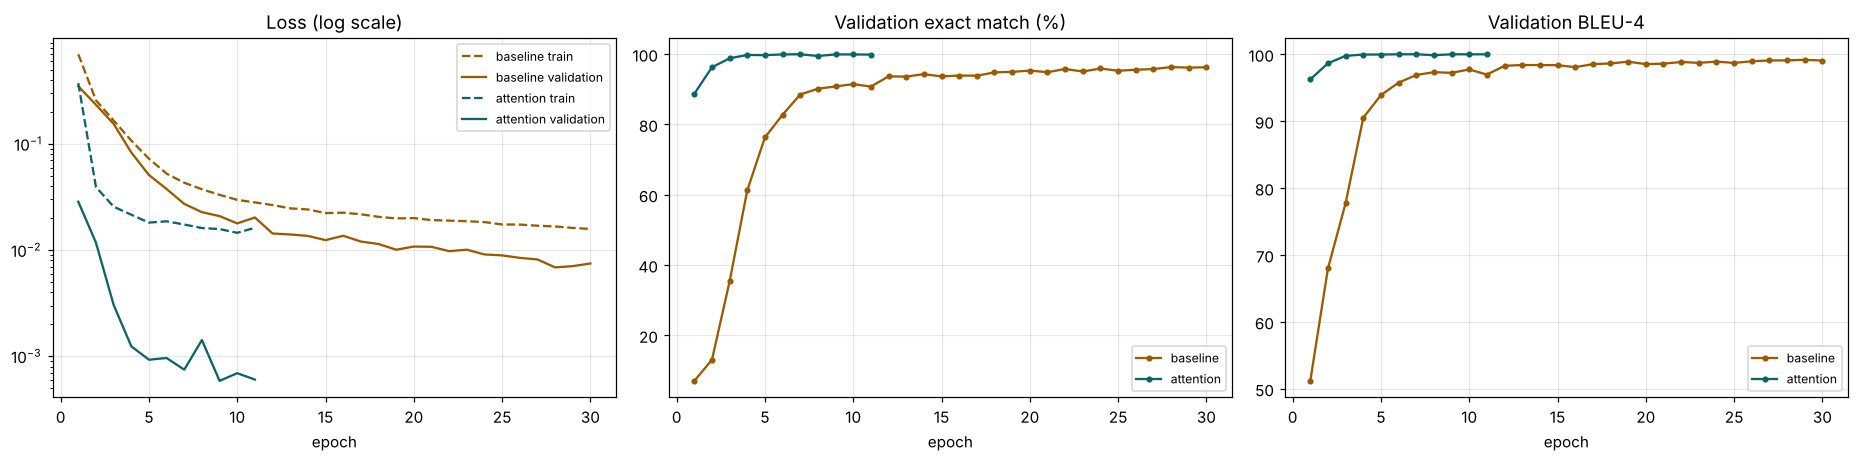

baseline: validation EM after epoch 1 = 7.0%, first epoch >= 88%: 7, best = 96.30%
attention: validation EM after epoch 1 = 88.7%, first epoch >= 88%: 1, best = 99.95%


In [31]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
colors = {"baseline": "#9A5B00", "attention": "#0B6465"}
for name, h in histories.items():
    ep = [x["epoch"] for x in h]
    ax[0].plot(ep, [x["train_loss"] for x in h], "--", color=colors[name], label=f"{name} train")
    ax[0].plot(ep, [x["val_loss"] for x in h], "-", color=colors[name], label=f"{name} validation")
    ax[1].plot(ep, [100 * x["val_em"] for x in h], "o-", ms=3, color=colors[name], label=name)
    ax[2].plot(ep, [x["val_bleu"] for x in h], "o-", ms=3, color=colors[name], label=name)
ax[0].set_yscale("log"); ax[0].set_title("Loss (log scale)"); ax[1].set_title("Validation exact match (%)"); ax[2].set_title("Validation BLEU-4")
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(NB_OUT / "learning_curves.png", dpi=130); plt.show()
for name, h in histories.items():
    first = next((x["epoch"] for x in h if x["val_em"] >= 0.88), None)
    print(f"{name}: validation EM after epoch 1 = {100 * h[0]['val_em']:.1f}%, first epoch >= 88%: {first}, "
          f"best = {100 * max(x['val_em'] for x in h):.2f}%")

**Reading.** The attention model is near its best after very few epochs, while the baseline improves slowly for about 30 epochs. Training and validation losses stay close (validation is even lower because dropout is only active in training), so there is no sign of overfitting on this data.

## 9. Evaluation

Three test sets, all with regexes the models have not been trained on (except 46 of the 50 handwritten ones):

- **New regexes** (1,884): new combinations and parameters, written in the training style.
- **New phrasings** (1,500): 11 sentence patterns held out of training.
- **Handwritten** (50): free wording.

Metrics: **exact match** (identical regex, in slot form), **same behaviour** (the generated regex accepts and rejects the same ~600 probe strings as the reference; a sampling test, not a proof), **BLEU-4** on regex tokens, **valid-regex rate**, and teacher-forced **perplexity** and **token accuracy**.

In [32]:
TESTS = {"test": "New regexes", "test_phrasing": "New phrasings", "test_handwritten": "Handwritten"}
reports, per_example = {}, {}
for name, m in models.items():
    for split in TESTS:
        res, pe = full_report(m, data, split, "greedy")
        reports[(name, split, "greedy")] = res
        per_example[(name, split)] = pe
rows = []
for (name, split, mode), r in reports.items():
    rows.append({"model": name, "test set": TESTS[split], "n": r["n"], "exact match %": 100 * r["exact_match"],
                 "same behaviour %": 100 * r["functional_acc"], "BLEU-4": r["bleu"], "valid %": 100 * r["valid_rate"],
                 "perplexity": r["perplexity"], "token acc %": 100 * r["token_acc"]})
results = pd.DataFrame(rows)
display(results.round(2))

,model,test set,n,exact match %,same behaviour %,BLEU-4,valid %,perplexity,token acc %
0,baseline,New regexes,1884,95.59,96.23,99.00,99.84,1.01,99.71
1,baseline,New phrasings,1500,81.20,83.33,96.80,100.00,1.03,98.98
2,baseline,Handwritten,50,92.00,92.00,97.42,100.00,1.07,98.87
3,attention,New regexes,1884,99.36,99.42,99.89,99.89,1.00,99.97
4,attention,New phrasings,1500,82.60,84.33,97.39,100.00,1.04,99.21
5,attention,Handwritten,50,96.00,96.00,97.64,100.00,1.04,99.35


model,attention,baseline
kind,,
AND of 2 or 3,99.4,92.5
OR of 2,99.0,99.0
negated condition,100.0,100.0
one condition,100.0,100.0


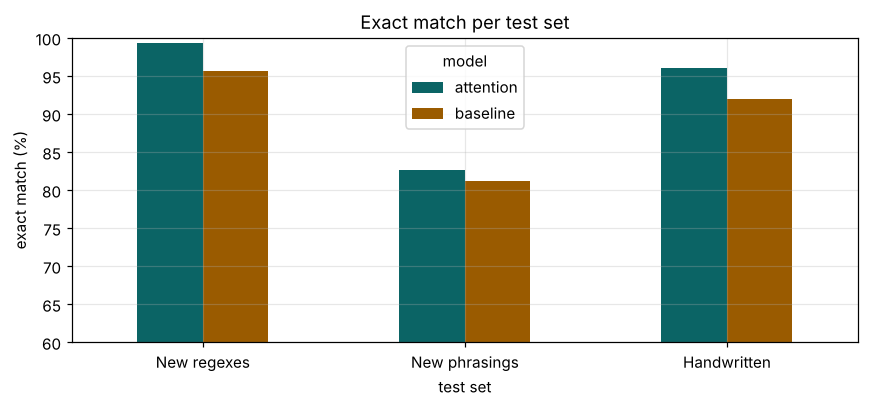

In [33]:
kind_rows = []
for name in models:
    r = reports[(name, "test", "greedy")]
    for k, label in [("atom", "one condition"), ("not", "negated condition"), ("and", "AND of 2 or 3"), ("or", "OR of 2")]:
        if f"em_kind_{k}" in r:
            kind_rows.append({"model": name, "kind": label, "n": r[f"n_kind_{k}"], "exact match %": 100 * r[f"em_kind_{k}"]})
kt = pd.DataFrame(kind_rows).pivot(index="kind", columns="model", values="exact match %").round(1)
display(kt)
ax = results.pivot(index="test set", columns="model", values="exact match %").reindex(TESTS.values()).plot(
    kind="bar", figsize=(8, 3.8), color=["#0B6465", "#9A5B00"], rot=0)
ax.set_ylabel("exact match (%)"); ax.set_ylim(60, 100); ax.set_title("Exact match per test set")
plt.tight_layout(); plt.show()

### 9.1 Greedy versus beam search

In [34]:
if RUN_BEAM:
    rows = []
    for name, m in models.items():
        for split in TESTS:
            t0 = time.time()
            res, _ = full_report(m, data, split, "beam", beam=5)
            g = reports[(name, split, "greedy")]
            rows.append({"model": name, "test set": TESTS[split], "greedy EM %": 100 * g["exact_match"],
                         "beam-5 EM %": 100 * res["exact_match"], "greedy same %": 100 * g["functional_acc"],
                         "beam-5 same %": 100 * res["functional_acc"], "beam seconds": round(time.time() - t0)})
    display(pd.DataFrame(rows).round(1))

,model,test set,greedy EM %,beam-5 EM %,greedy same %,beam-5 same %,beam seconds
0,baseline,New regexes,95.6,95.7,96.2,96.3,67
1,baseline,New phrasings,81.2,81.6,83.3,83.5,61
2,baseline,Handwritten,92.0,92.0,92.0,92.0,1
3,attention,New regexes,99.4,99.4,99.4,99.5,86
4,attention,New phrasings,82.6,82.6,84.3,84.3,73
5,attention,Handwritten,96.0,96.0,96.0,96.0,2


**Reading.** Beam search barely changes the results: the models, especially the attention one, are so confident that the best sequence is almost always the greedy one. (Our beam search stops only when no open hypothesis can still beat the best finished one; a first version that stopped as soon as five hypotheses had ended discarded good outputs.)

## 10. Analysis

### 10.1 Attention heatmaps

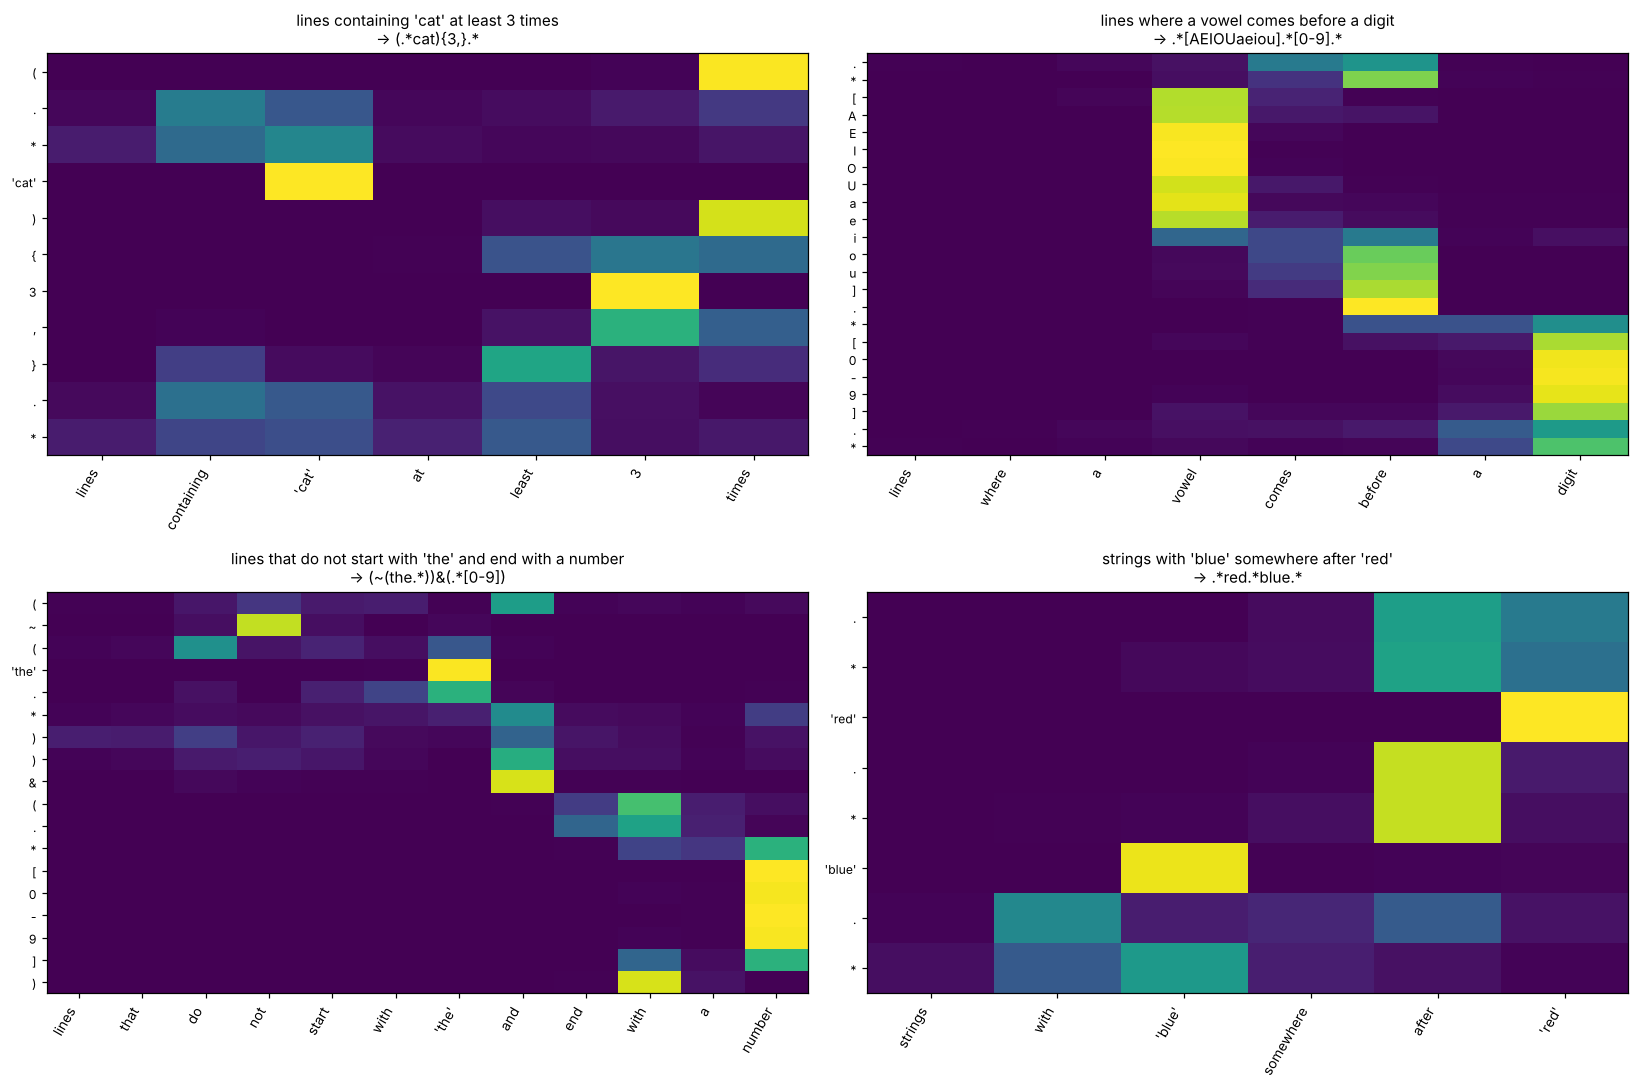

In [35]:
def translate(model, text, return_attention=False):
    toks = tokenize_src_veri(text)
    lits = anonymize(text)[1]
    row = {"src_ids": src_vocab.encode(toks[:MAX_SRC_LEN]), "tgt_ids": [SOS_ID, EOS_ID]}
    src, src_len, _ = collate([row])
    res = model.greedy_decode(src, src_len, return_attention=return_attention)
    ids, att = res if isinstance(res, tuple) else (res, None)
    out = tgt_vocab.decode(ids[0].tolist())
    rx = deanonymize(detokenize_tgt(out), lits)
    return (rx, toks, out, att[0, :len(out)].numpy(), lits) if return_attention else rx

texts = ["lines containing 'cat' at least 3 times", "lines where a vowel comes before a digit",
         "lines that do not start with 'the' and end with a number", "strings with 'blue' somewhere after 'red'"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, text in zip(axes.ravel(), texts):
    rx, toks, out, a, lits = translate(models["attention"], text, return_attention=True)
    show = lambda t: f"'{lits[int(t[3])]}'" if re.fullmatch(r"__w\d__", t) else t
    ax.imshow(a, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(toks))); ax.set_xticklabels([show(t) for t in toks], rotation=60, ha="right", fontsize=9)
    ax.set_yticks(range(len(out))); ax.set_yticklabels([show(t) for t in out], fontsize=8)
    ax.set_title(f"{text}\n-> {rx}", fontsize=10); ax.grid(False)
plt.tight_layout(); plt.savefig(NB_OUT / "attention_examples.png", dpi=130); plt.show()

**Reading.** Each generated token attends to the words that justify it: counts to the number in the sentence, each slot to its quoted literal, `~` to "not", `&` to "and", `[AEIOUaeiou]` to "vowel". For "'blue' somewhere after 'red'" the regex must start with `red`, and the decoder indeed attends to the last word of the sentence first: a reordering that a single summary vector cannot do well.

### 10.2 Generated examples

In [36]:
def show_examples(name, split, kind, k=6, seed=0):
    pe = per_example[(name, split)]
    if kind == "correct":
        sel = [x for x in pe if x["em"]]
    elif kind == "equivalent":
        sel = [x for x in pe if x["functional"] and not x["em"]]
    else:
        sel = [x for x in pe if not x["functional"]]
    sel = random.Random(seed).sample(sel, min(k, len(sel)))
    rows = []
    for x in sel:
        lits = anonymize(x["src"])[1]
        rows.append({"description": x["src"], "reference": deanonymize(x["ref"], lits), "generated": deanonymize(x["pred"], lits)})
    return pd.DataFrame(rows)

for split in TESTS:
    display(Markdown(f"**{TESTS[split]}: correct (attention model)**"))
    display(show_examples("attention", split, "correct", 4))
    display(Markdown(f"**{TESTS[split]}: wrong (attention model)**"))
    display(show_examples("attention", split, "wrong", 5))

**New regexes: correct (attention model)**

,description,reference,generated
0,regex matching lines which start with a vowel or a numeral,([AEIOUaeiou].*)|([0-9].*),([AEIOUaeiou].*)|([0-9].*)
1,"lines that contain ""tion"" repeated four times in a row and contain four or more upper-case letters","(.*(tion){4,}.*)&((.*[A-Z]){4,}.*)","(.*(tion){4,}.*)&((.*[A-Z]){4,}.*)"
2,regex matching any string that does not contain an uppercase letter immediately followed by the substring 'phone',~(.*[A-Z]phone.*),~(.*[A-Z]phone.*)
3,a regular expression for a string that has a vowel and contains the substring 'abc' immediately after the string 'cat',(.*[AEIOUaeiou].*)&(.*catabc.*),(.*[AEIOUaeiou].*)&(.*catabc.*)


**New regexes: wrong (attention model)**

,description,reference,generated
0,get any line which ends with the text 'forest' or the sequence 'berlin',(.*forest)|(.*berlin),(.*forest)|(.*berlin.*)
1,"the lines that begin with a letter, contain 'rocket' and are longer than two characters","([A-Za-z].*)&(.*rocket.*)&(~(.{0,2}))","([A-Za-z].*)&(~(.{0,2}))"
2,"match text lines that contain a vowel less than three times, begin with a numeric character, and do not contain an u...","(~((.*[AEIOUaeiou]){3,}.*))&([0-9].*)&(~(.*[A-Z].*[AEIOUaeiou].*))","(~((.*[AEIOUaeiou]){3,}.*))&([0-9].*)&(~(.*[A-Z].*[AEIOUaeio"
3,I need strings ending in the sequence 'purple' or the substring 'offer',(.*purple)|(.*offer),(.*purple)|(.*offer.*)
4,find all lines which finish with the text 'z' or the string 'Paris',(.*z)|(.*Paris),(.*z)|(.*Paris.*)


**New phrasings: correct (attention model)**

,description,reference,generated
0,I want all strings containing 5 consecutive copies of 'purple' or ending with an uppercase letter,"(.*(purple){5,}.*)|(.*[A-Z])","(.*(purple){5,}.*)|(.*[A-Z])"
1,show me all lines where a blank space does not appear before a number and the text begins with a lower-case letter,(~(.* .*[0-9].*))&([a-z].*),(~(.* .*[0-9].*))&([a-z].*)
2,"get all strings with at most seven characters, containing 'NASA' and made only of letters","(.{0,7})&(.*NASA.*)&([A-Za-z]+)","(.{0,7})&(.*NASA.*)&([A-Za-z]+)"
3,show me all lines that both end with the substring 'foo' and contain the sequence 'yellow' less than 4 times,"(.*foo)&(~((.*yellow){4,}.*))","(.*foo)&(~((.*yellow){4,}.*))"


... (2 outputs left out)

**Handwritten: correct (attention model)**

,description,reference,generated
0,lines that contain 'tunis' or begin with 'Tunis',(.*tunis.*)|(Tunis.*),(.*tunis.*)|(Tunis.*)
1,lines where 'qu' is directly followed by a vowel,.*qu[AEIOUaeiou].*,.*qu[AEIOUaeiou].*
2,text that begins with 'Dear',Dear.*,Dear.*
3,lines where a vowel appears before a digit,.*[AEIOUaeiou].*[0-9].*,.*[AEIOUaeiou].*[0-9].*


**Handwritten: wrong (attention model)**

,description,reference,generated
0,lines of at most 10 characters that contain a digit,"(.{0,10})&(.*[0-9].*)","(.{0,10})|(.*[0-9].*)"
1,lines with no digits at all,~(.*[0-9].*),".{0,9}"


### 10.3 Error analysis

In [37]:
def error_type(x):
    p, g = x["pred"], x["ref"]
    if not x["valid"]:
        return "invalid regex"
    if re.sub(r"\d", "N", p) == re.sub(r"\d", "N", g):
        return "wrong number only"
    if re.sub(r"__w\d__", "W", p) == re.sub(r"__w\d__", "W", g):
        return "literals swapped"
    if p.count("~") != g.count("~"):
        return "negation missing or extra"
    if ("&" in p) != ("&" in g) or ("|" in p) != ("|" in g):
        return "wrong connective (and/or)"
    if re.sub(r"\[[^\]]*\]", "C", p) == re.sub(r"\[[^\]]*\]", "C", g):
        return "wrong character class"
    return "other structure error"

rows = []
for (name, split), pe in per_example.items():
    c = Counter(error_type(x) for x in pe if not x["functional"])
    c["exact"] = sum(x["em"] for x in pe)
    c["equivalent, written differently"] = sum(1 for x in pe if x["functional"] and not x["em"])
    rows.append({"model": name, "test set": TESTS[split], **c})
cols = ["exact", "equivalent, written differently", "other structure error", "negation missing or extra",
        "wrong connective (and/or)", "wrong character class", "wrong number only", "literals swapped", "invalid regex"]
err = pd.DataFrame(rows).reindex(columns=["model", "test set"] + cols).fillna(0).set_index(["model", "test set"]).astype(int)
display(err)

exact  equivalent, written differently  other structure error  negation missing or extra  wrong connective (and/or)  wrong character class  wrong number only  \
model     test set                                                                                                                                                                       
baseline  New regexes     1801                               12                     49                          3                          0                     11                  5   
          New phrasings   1218                               32                    168                         48                          0                     19                 15   
          Handwritten       46                                0                      0                          2                          2                      0                  0   
attention New regexes     1872                                1                      9                          0                          0                      0                  0   
          New phrasings   1239                               26                    156                         68                          0                      8                  3   
          Handwritten       48                                0                      0                          1                          1                      0                  0   

                         literals swapped  invalid regex  
model     test set                                        
baseline  New regexes                   0              3  
          New phrasings                 0              0  
          Handwritten                   0              0  
attention New regexes                   0              2  
          New phrasings                 0              0  
          Handwritten                   0              0

**Reading.** Almost every output is a valid regex: the syntax is learned. Errors are about meaning. On new regexes the attention model makes only a handful of mistakes, most of them on one structure absent from training ("ends with X or Y", where the second ending becomes "contains") and on outputs cut at the 60-token limit. On held-out phrasings the dominant errors are a condition read as another one (for example the held-out "have X at the end" read as "starts with" or "contains") and flipped negations ("no fewer than N" read as "fewer than N"): the model has learned constructions rather than the meaning of each word independently.

## 11. Interactive demo

Put literal text in quotes. The regex must match the whole line; `&` means and, `~` means not.

In [38]:
def demo(text, lines):
    print("English :", text)
    for name in ("attention", "baseline"):
        rx = translate(models[name], text)
        ast_ = compile_regex(rx)
        res = ["MATCH" if (ast_ and full_match(ast_, l)) else "no" for l in lines]
        print(f"  {name:9s}: {rx:40s}", " ".join(f"{l!r}:{r}" for l, r in zip(lines, res)))
    print()

demo("lines containing 'cat' at least 2 times", ["cat", "cat and cat", "catcat"])
demo("lines containing 'cat' 2 times in a row", ["cat", "cat and cat", "catcat"])
demo("lines that start with a capital letter and end with a number", ["Hello 5", "hello 5", "Abc"])
demo("lines that contain 'error' and do not contain 'warning'", ["error 42", "warning: error", "all good"])
demo("lines where 'price' comes before 'total'", ["price 10, total 12", "total then price"])
demo("lines made only of digits", ["2024", "20a4", ""])
demo("lines with no digits at all", ["hello", "abc1"])                  # a known failure
demo("lines that contain 'x' no fewer than 3 times", ["xxx", "xx"])     # a known failure

English : lines containing 'cat' at least 2 times
  attention: (.*cat){2,}.*                            'cat':no 'cat and cat':MATCH 'catcat':MATCH
  baseline : (.*cat){2,}.*                            'cat':no 'cat and cat':MATCH 'catcat':MATCH

English : lines containing 'cat' 2 times in a row
  attention: .*(cat){2,}.*                            'cat':no 'cat and cat':no 'catcat':MATCH
  baseline : .*(cat){2,}.*                            'cat':no 'cat and cat':no 'catcat':MATCH

English : lines that start with a capital letter and end with a number
  attention: ([A-Z].*)&(.*[0-9])                      'Hello 5':MATCH 'hello 5':no 'Abc':no
  baseline : ([A-Z].*)&(.*[0-9])                      'Hello 5':MATCH 'hello 5':no 'Abc':no

English : lines that contain 'error' and do not contain 'warning'
  attention: (.*error.*)&(~(.*warning.*))             'error 42':MATCH 'warning: error':no 'all good':no
  baseline : (.*error.*)&(~(.*warning.*))             'error 42':MATCH 'warning: erro

  baseline : (.*[0-9]){2,}.*                          'hello':no 'abc1':no

English : lines that contain 'x' no fewer than 3 times
  attention: ~((.*x){3,}.*)                           'xxx':no 'xx':MATCH
  baseline : ~((.*x){3,}.*)                           'xxx':no 'xx':MATCH



In [39]:
# try your own description here
demo("lines that begin with 'Dear' or end with '!'", ["Dear Sir", "Hello!", "Hi."])

English : lines that begin with 'Dear' or end with '!'
  attention: (Dear.*)|(.*!)                           'Dear Sir':MATCH 'Hello!':MATCH 'Hi.':no
  baseline : (Dear.*)|(.*!)                           'Dear Sir':MATCH 'Hello!':MATCH 'Hi.':no



## 12. Discussion and conclusion

**Does the model learn the task?** On the distribution it was trained on, yes: the attention model generates almost all regexes it has never seen exactly right, with valid syntax and near-perfect BLEU. Attention is the decisive component for combinations of conditions: the baseline, even trained twice as long, makes several times more errors on new regexes, concentrated in AND combinations where one vector has to carry two or three conditions with their literals and numbers. Attention also learns several times faster.

**Where it fails.** New wording. On sentence patterns held out of training, exact match drops by about 17 points, and here the long-trained baseline is close behind: what limits both models is the variety of the language they were trained on, not the architecture. The errors are interpretable (a held-out construction mapped to a known one, negation words in unfamiliar constructions).

**Strengths.** Small model (1.4M parameters) trained on a CPU, interpretable attention, no pretrained component, any literal word thanks to slots, and labels that are verified rather than assumed.

**Limitations.** The English is generated from templates, so the in-distribution score is optimistic; the held-out-phrasing and handwritten tests are the honest estimates, and the handwritten set is small (50). Behavioural equivalence is a sampling test (we found one false "equivalent" in the project analysis). Outputs are capped at 60 tokens.

**Possible improvements.** Human paraphrases of the generated sentences to diversify the training language; more constructions per condition, especially for negation; a copy mechanism for unquoted literals; grammar-constrained decoding; exact DFA-based equivalence.

**Conclusion.** A from-scratch LSTM encoder-decoder with additive attention translates English descriptions into regular expressions. Training it on verified labels, rather than on a benchmark whose labels sometimes contradict their English, turns a 45% exact-match system into one that is nearly perfect on new regexes and solid on new wording and handwritten requests. The main lessons: check the labels before trusting a metric, and always evaluate outside the distribution the data generator produces.

The full technical report (`results/REPORT.pdf`), the slides and an in-browser demo (`site/`) accompany this notebook.